In [1]:
'''
fix sats to work after de-duplication
'''

'\nfix sats to work after de-duplication\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"
df_inference= pd.read_csv(base_path+"df_inf_wdups")

In [8]:
df_inference.drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9",
                                                    "Unnamed: 0.10"
                                                    ])

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local,...,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup,num_in_file_in_star
0,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,22.500000,1273.000000,14.0,1273.0,1665.0,10.000000,0.114091,...,52.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,267.0,0.0,0.0,0.0,[1],0.0,194.0
1,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,38.000000,1273.000000,7.0,1273.0,1665.0,10.000000,0.060265,...,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[0 2],1.0,194.0
2,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,56.000000,1273.000000,15.0,1273.0,1665.0,10.000000,0.189495,...,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[1 3],0.0,194.0
3,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,76.000000,1273.000000,11.0,1273.0,1665.0,10.000000,0.184024,...,54.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,265.0,0.0,0.0,0.0,[2 5 6],1.0,194.0
4,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,77.500000,2011.000000,2.0,2023.0,1520.0,2.000000,0.095158,...,248.0,[ 0 1 2 3 73 81 111 140 219 254 256 2...,[ 5 6 7 8 9 10 11 13 14 15 17 ...,248.0,0.0,0.0,0.0,[],0.0,268.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,2990.500000,1876.000000,2.0,1889.0,2541.0,3.000000,0.083719,...,148.0,[894481 894482 894484 894485 894487 894488 894...,[894480 894483 894486 894492 894494 894498 894...,148.0,0.0,0.0,0.0,[894768 894769 894771],1.0,174.0
894771,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,3005.208333,1877.833333,24.0,1889.0,2541.0,1.166667,0.102663,...,97.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894620 894627 894632 894...,197.0,0.0,0.0,0.0,[894769 894770 894772],0.0,174.0
894772,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,3020.800000,1878.000000,10.0,1889.0,2541.0,1.000000,0.080556,...,52.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894635 894636 894...,201.0,0.0,0.0,0.0,[894771],1.0,174.0
894773,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,3047.500000,1878.000000,4.0,1889.0,2541.0,1.000000,0.202717,...,49.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894639 894640 894...,203.0,0.0,0.0,0.0,[894774],0.0,174.0


In [11]:
df_nodup = df_inference[df_inference['is_smaller_dup']==0].drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9",
                                                    "Unnamed: 0.10"
                                                    ])


In [12]:
df_nodup['index_copy']=df_nodup.index

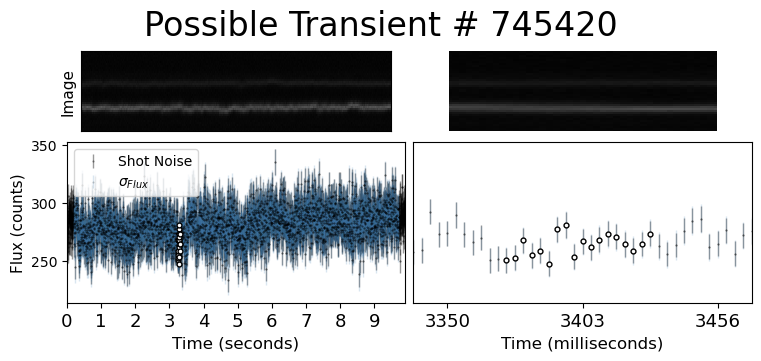

In [15]:
rff.plot_time_series_again_aperture(df_nodup,745420)

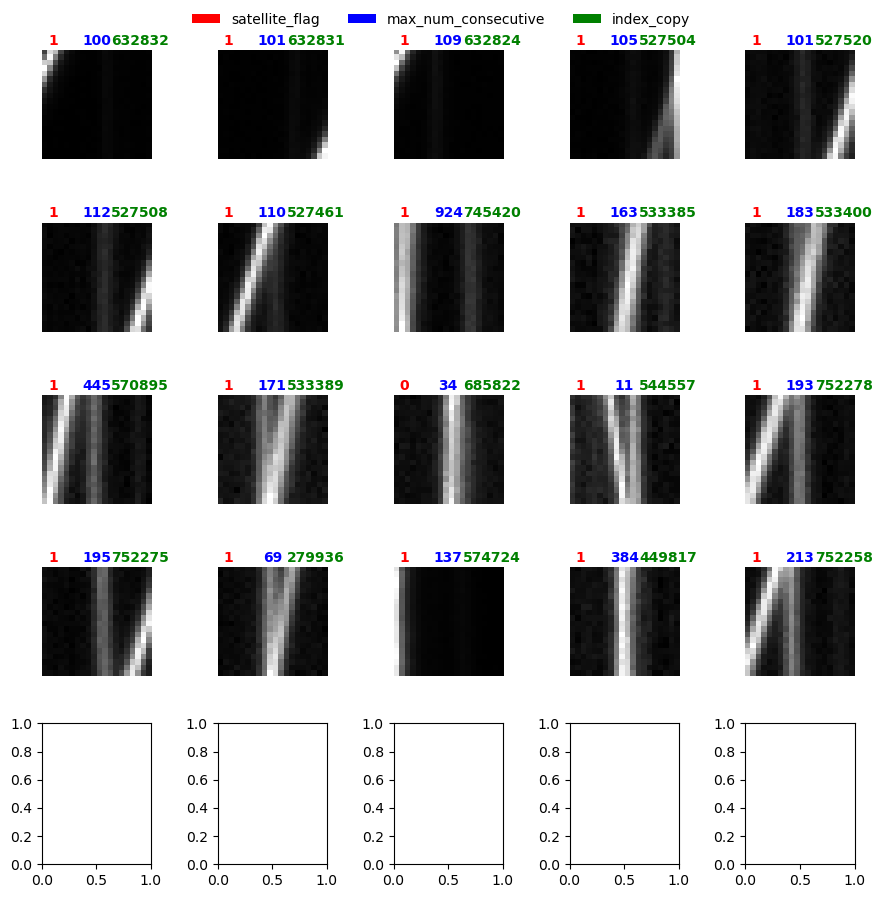

In [13]:
rff.inspect_df_w_stamp_color(df_nodup[df_nodup['Diff']<5].sort_values('snr_local_new',ascending=False)[:20], titlecol=['satellite_flag','max_num_consecutive','index_copy' ])

In [160]:
subset = df_nostreaks[df_nostreaks['Diff']<5].sort_values('snr_local_new',ascending=False)[:1000]

In [17]:
subset

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local,...,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup,num_in_file_in_star,index_copy
632832,ztf_20221020154120_000640_zi_c15_x_0028.,3,pos,580.555556,2830.666667,9.0,2841.0,2144.0,0.333333,0.018277,...,[632819 632820 632825 632826 632828 632830 632...,[632821 632822 632823 632824 632827 632829 632...,100.0,1.0,1.0,1.0,[],0.0,3.0,632832
632831,ztf_20221020154120_000640_zi_c15_x_0028.,3,pos,529.500000,2828.000000,2.0,2841.0,2144.0,3.000000,0.202683,...,[632819 632820 632825 632826 632828 632829 632...,[632821 632822 632823 632824 632827 632830 632...,101.0,1.0,1.0,1.0,[632830],0.0,3.0,632831
632824,ztf_20221020154120_000640_zi_c15_x_0028.,3,pos,292.955556,2969.088889,45.0,2976.0,2240.0,3.088889,0.207368,...,[632819 632820 632821 632822 632823 632860 632...,[632825 632826 632827 632828 632829 632830 632...,109.0,1.0,1.0,1.0,[],0.0,6.0,632824
527504,ztf_20221020148032_000686_zg_c16_x_0014.,1,neg,357.000000,1301.000000,3.0,1312.0,494.0,1.000000,0.823127,...,[527455 527460 527462 527463 527464 527465 527...,[527452 527453 527454 527456 527457 527458 527...,105.0,1.0,1.0,1.0,[527505],0.0,32.0,527504
527520,ztf_20221020148032_000686_zg_c16_x_0014.,1,neg,678.500000,1198.100000,10.0,1209.0,337.0,0.900000,0.519682,...,[527455 527464 527465 527467 527468 527469 527...,[527452 527453 527454 527456 527457 527458 527...,101.0,1.0,1.0,1.0,[527519],0.0,2.0,527520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
865875,ztf_20221020154120_000640_zi_c04_x_0026.,4,neg,614.000000,1939.375000,8.0,1951.0,2854.0,1.625000,0.139803,...,[865556 865557 865558 865559 865560 865561 865...,[865609 865610 865611 865612 865613 865614 865...,308.0,0.0,0.0,0.0,[],0.0,265.0,865875
359593,ztf_20221020297847_000449_zr_c13_x_0000.,3,neg,2654.500000,1998.000000,2.0,2010.0,2683.0,2.000000,0.333400,...,[359290 359292 359293 359294 359295 359296 359...,[359288 359289 359305 359314 359315 359328 359...,227.0,0.0,0.0,0.0,[],0.0,95.0,359593
886847,ztf_20221020294271_000449_zr_c06_x_0013.,4,neg,1092.285714,1855.571429,7.0,1865.0,275.0,0.571429,0.479425,...,[886839 886840 886843 886844 886845 886846 886...,[886834 886835 886836 886837 886838 886841 886...,13.0,1.0,0.0,0.0,[],0.0,17.0,886847
791806,ztf_20221020148032_000686_zg_c02_x_0025.,2,neg,421.000000,294.000000,13.0,301.0,1454.0,3.000000,0.396376,...,[791292 791294 791303 791306 791312 791320 791...,[791293 791295 791296 791297 791298 791299 791...,625.0,0.0,0.0,0.0,[791807 791809 791812 791813 791814],0.0,22.0,791806


In [159]:
df_nostreaks = df_nodup[df_nodup['num_in_file_in_star']<10]

In [231]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [232]:
subset11 = rff.add_num_consecutive(subset, df_larger=df_nostreaks[df_nostreaks['Diff']<5])
#removing num_in_file_in_star>=10 and requiring sobel norm diffmax<10 for diagonals

In [183]:
subset10 = rff.add_num_consecutive(subset, df_larger=df_nostreaks[df_nostreaks['Diff']<5])
#removing num_in_file_in_star>=10 and requiring det size > 2 for diagonals

In [162]:
subset9 = rff.add_num_consecutive(subset, df_larger=df_nostreaks[df_nostreaks['Diff']<5])
#removing num_in_file_in_star>=10

In [152]:
subset8 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])
#detection size > 5

In [132]:
subset7 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])
#detection size >10

KeyboardInterrupt: 

In [110]:
subset6 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])
#pos only

In [104]:
subset5 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])
#same polarity

In [41]:
subset3 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])

In [135]:
subset4 = rff.add_num_consecutive(subset, df_larger=df_nodup[df_nodup['Diff']<5])
#standard

In [32]:
subset2 = rff.add_num_consecutive(subset, df_larger=df_nodup)

(array([ 78.,  85.,  86.,  68.,  90., 105.,  79.,  50.,  57.,  61.,  26.,
         40.,  28.,  28.,  22.,  14.,  15.,  17.,   8.,   6.,   9.,   4.,
          8.,   1.,   3.,   3.,   1.,   1.,   0.,   2.,   0.,   1.,   0.,
          1.,   1.,   0.,   0.,   0.,   1.,   1.]),
 array([  0.   ,  14.425,  28.85 ,  43.275,  57.7  ,  72.125,  86.55 ,
        100.975, 115.4  , 129.825, 144.25 , 158.675, 173.1  , 187.525,
        201.95 , 216.375, 230.8  , 245.225, 259.65 , 274.075, 288.5  ,
        302.925, 317.35 , 331.775, 346.2  , 360.625, 375.05 , 389.475,
        403.9  , 418.325, 432.75 , 447.175, 461.6  , 476.025, 490.45 ,
        504.875, 519.3  , 533.725, 548.15 , 562.575, 577.   ]),
 <BarContainer object of 40 artists>)

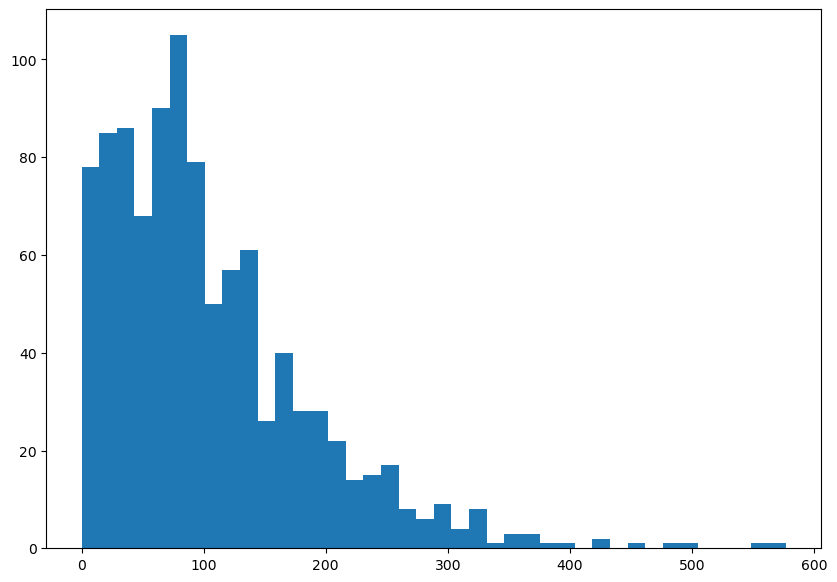

In [28]:
plt.hist(subsetagain['max_num_consecutive_new'],bins=40)

In [43]:
subset3.loc[745420, "possible_up_indices_new"]

array([744999, 745011, 745013, 745016, 745021, 745028, 745038, 745056,
       745058, 745069, 745074, 745076, 745079, 745088, 745108, 745121,
       745122, 745137, 745138, 745144, 745156, 745161, 745170, 745181,
       745186, 745199, 745205, 745215, 745236, 745246, 745254, 745258,
       745268, 745279, 745281, 745285, 745296, 745305, 745328, 745341,
       745348, 745359, 745364, 745384, 745389, 745391, 745404, 745418,
       745419, 745457, 745511, 745732, 745746, 745778, 745841, 745967,
       745997, 746102, 746112, 746156, 746211, 746276, 746289, 746291,
       746293, 746295, 746297, 746298, 746299, 746301, 746302, 746305,
       746311, 746313, 746317, 746320, 746321, 746323, 746324, 746327,
       746331, 746332, 746333, 746336, 746338, 746341, 746342, 746343,
       746346, 746348, 746350, 746353, 746354, 746355, 746357, 746359,
       746360, 746366, 746367, 746370, 746373, 746374, 746376, 746379,
       746384, 746386, 746387, 746388, 746392, 746393, 746395, 746396,
      

In [136]:
subset4.loc[632832, "possible_down_indices_new"]

array([632821, 632824, 632827, 632833, 632837, 632838, 632839, 632840,
       632841, 632842, 632843, 632844, 632845, 632846, 632848, 632849,
       632850, 632851, 632852, 632853, 632855, 632856, 632857, 632859,
       632867, 632877, 632878, 632879, 632880, 632881, 632883, 632885,
       632886, 632887, 632888, 632890, 632891, 632892, 632893, 632894,
       632895, 632896, 632897, 632898, 632900, 632901, 632902, 632908,
       632909, 632910, 632912, 632914, 632916, 632917, 632920, 632921,
       632922, 632924, 632925, 632926, 632928, 632929, 632930, 632931,
       632932, 632933, 632934, 632935, 632936, 632937, 632938, 632940])

In [157]:
subset4.loc[334274, "possible_down_indices_new"]

array([334281, 334293, 334305, 334314, 334324, 334333, 334334, 334336,
       334349, 334359, 334362, 334369, 334373, 334376, 334386, 334401,
       334413, 334424, 334435, 334449, 334457, 334459, 334467, 334473,
       334481, 334486, 334488, 334496, 334504, 334505, 334516, 334530,
       334538, 334550, 334553, 334554, 334560, 334563, 334570, 334571,
       334586, 334589, 334598, 334599, 334608, 334633, 334635, 334656,
       334672, 334684, 334687, 334691, 334698, 334701, 334710, 334719,
       334724, 334730, 334735, 334744, 334755, 334770, 334773, 334788,
       334792, 334803, 334810, 334811, 334837, 334852, 334858, 334867,
       334868, 334871, 334878, 334893, 334921, 334922, 334935, 334937,
       334942, 334953, 334961, 334967, 334972, 334977, 334987, 334989,
       335026, 335031, 335033, 335044, 335054, 335065, 335078, 335097,
       335099, 335121, 335129, 335134, 335170, 335173, 335176, 335181,
       335193, 335208, 335218, 335225, 335228, 335236, 335237, 335238,
      

In [155]:
subset4.loc[334274, "possible_up_indices_new"]

array([334212, 334213, 334219, 334231, 334234, 334243, 334244, 334256,
       334282, 334284, 334292, 334345, 334348, 334397, 334412, 334423,
       334445, 334493, 334824, 334829, 334836, 334848, 334890, 334915,
       334933, 334991, 334996, 335012, 335090, 335111, 335125, 335222,
       335227, 335230, 335231, 335232, 335233, 335240, 335246, 335260,
       335275, 335279, 335286, 335297, 335312, 335317, 335318, 335321,
       335326, 335336, 335340, 335349, 335362, 335375, 335387, 335395,
       335398, 335408, 335419, 335428, 335446, 335461, 335473, 335480,
       335483, 335491, 335510, 335513, 335525, 335533, 335538])

In [213]:
df_nodup.loc[[669689]]

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local,...,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup,num_in_file_in_star,index_copy
669689,ztf_20221020141806_000686_zi_c09_x_0015.,4,pos,2904.5,2279.0,2.0,2291.0,2088.0,2.0,0.048183,...,[669658 669659 669660 669661 669662 669663 669...,[669690 669691 669692 669693 669694 669805 669...,141.0,1.0,0.0,0.0,[],0.0,1.0,669689


In [210]:
subset9.loc[669689]

filename                              ztf_20221020141806_000686_zi_c09_x_0015.
quad                                                                         4
type                                                                       pos
row_from_nn                                                             2904.5
col_from_nn                                                             2279.0
detection_size                                                             2.0
closest_x                                                               2291.0
closest_y                                                               2088.0
Diff                                                                       2.0
snr_local                                                             0.048183
snr_global                                                            0.151375
noise_local                                                           162.7358
noise_global                                        

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020138241_000686_zi_c14_x_0023._extraction_predsarray_3_predsarray.npy


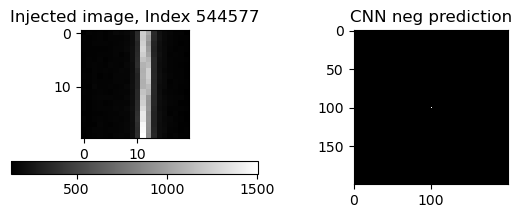

In [256]:
for index in [544577]:#31244,31253, 31264, 31265, 31274, 31307, 31308,31242, 31257, 31262, 31269]:
    #744999, 745011, 745013, 745016, 745021, 745028, 745038, 745056,
       # 745058, 745069, 745074]:#745420, 744999, 745011, 745013, 745016, 745021]: #449817,449332, 449333, 449335, 449336, 449337]:#[425,426,427]:#series.index:#[2, 865, 874, 2057]:
    rff.inspect_stamp_and_map(df_nodup, index, size=100, eff=False)

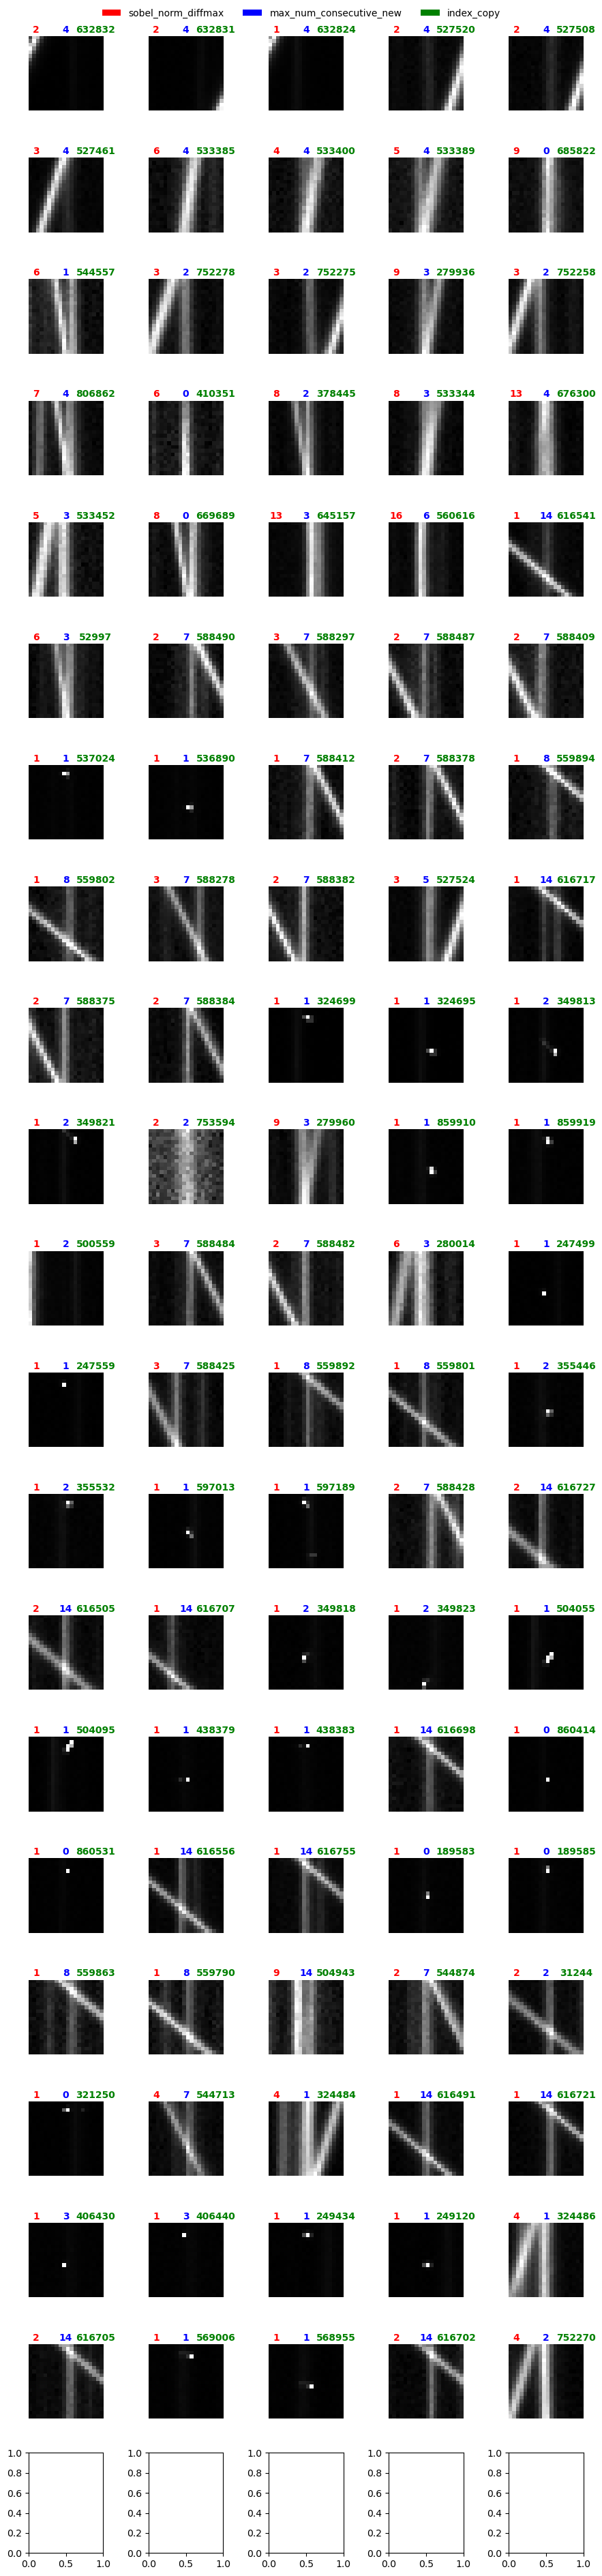

In [164]:
rff.inspect_df_w_stamp_color(subset9.sort_values('snr_local_new',ascending=False)[:100], titlecol=['sobel_norm_diffmax','max_num_consecutive_new','index_copy' ])

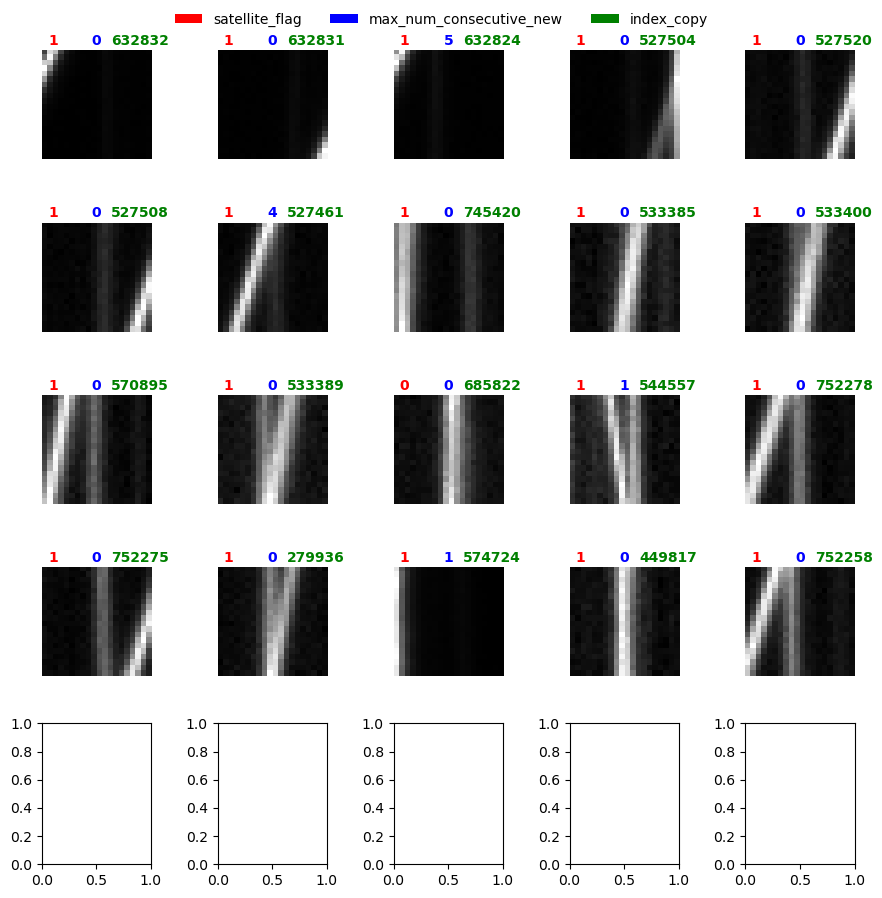

In [115]:
rff.inspect_df_w_stamp_color(subset2.sort_values('snr_local_new',ascending=False)[:20], titlecol=['satellite_flag','max_num_consecutive_new','index_copy' ])

In [141]:
subset4.iloc[0]

filename                              ztf_20221020154120_000640_zi_c15_x_0028.
quad                                                                         3
type                                                                       pos
row_from_nn                                                         580.555556
col_from_nn                                                        2830.666667
detection_size                                                             9.0
closest_x                                                               2841.0
closest_y                                                               2144.0
Diff                                                                  0.333333
snr_local                                                             0.018277
snr_global                                                            0.061245
noise_local                                                        2651.665786
noise_global                                        

In [229]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

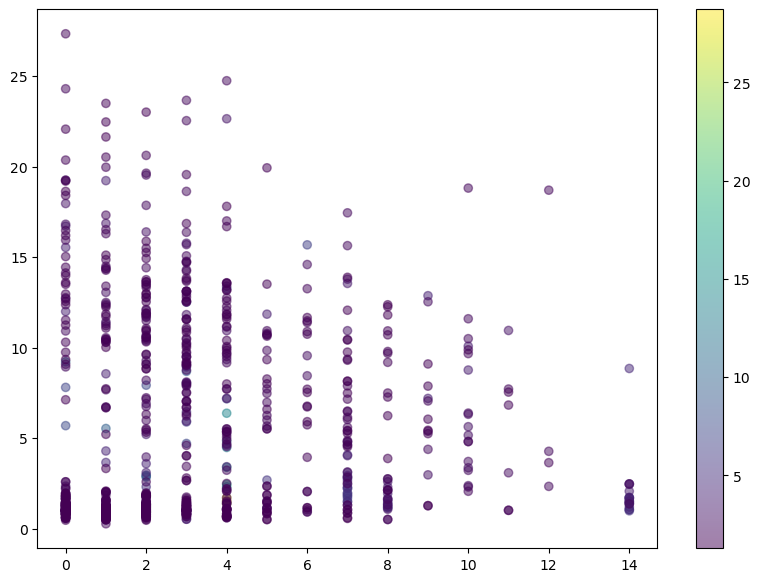

In [175]:
plt.scatter(subset9['max_num_consecutive_new'],subset9['sobel_norm_diffmax'],c=subset9['snr_local_new'], cmap='viridis',alpha=.5)
plt.colorbar()

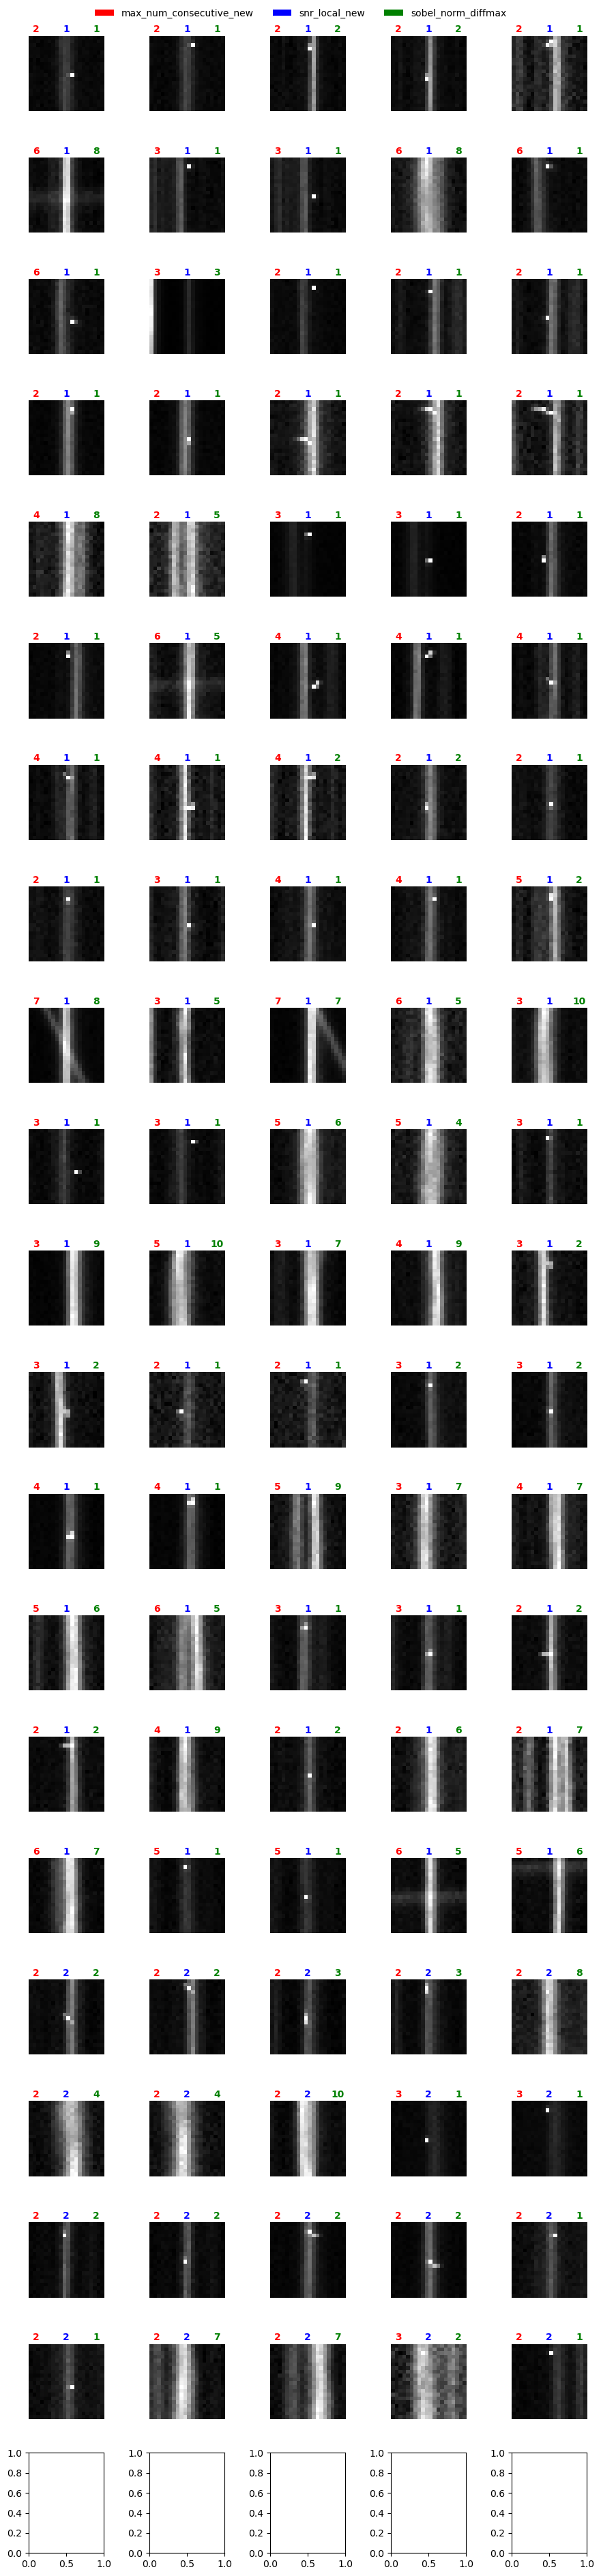

In [185]:
rff.inspect_df_w_stamp_color(subset10[((subset10['sobel_norm_diffmax']<10)*(subset10['max_num_consecutive_new']>1))].sort_values('snr_local_new', ascending=True)[:100], titlecol=['max_num_consecutive_new','snr_local_new', 'sobel_norm_diffmax' ])

In [189]:
todrop = subset9[(subset9['sobel_norm_diffmax']<8)*(subset9['max_num_consecutive_new']>3)].index

In [190]:
maybe = subset9.drop(todrop)

In [270]:
def add_sat_and_proximity(df):
    df = df.copy()
    df['sat_flag'] = np.zeros(len(df))
    df['sat_neighbor'] = np.zeros(len(df))
    for i, row in df.iterrows():
        if ((row['sobel_norm_diffmax']<5)*(row['max_num_consecutive_new']>1)*(row['snr_local_new']>=2)):
            df.loc[i,'sat_flag']=1
    for i, satrow in df[df['sat_flag']==1].iterrows():
        subsection = df[(df["filename"]==fname) * (df["quadrant"]==quad)]
        original_col = satrow["col_from_nn"]
        original_row = satrow["row_from_nn"]
        for i, neighborrow in subsection.iterrows():
            if (np.abs(neighborrow["col_from_nn"] - original_col)<40) * (np.abs(neighborrow["row_from_nn"] - original_row)<40):
                df.loc[i,'sat_neighbor']=1
    return df

In [271]:
df_neigh11 = add_sat_and_proximity(subset11)

In [204]:
df_neigh.iloc[0]

filename                              ztf_20221020154120_000640_zi_c15_x_0028.
quad                                                                         3
type                                                                       pos
row_from_nn                                                         580.555556
col_from_nn                                                        2830.666667
detection_size                                                             9.0
closest_x                                                               2841.0
closest_y                                                               2144.0
Diff                                                                  0.333333
snr_local                                                             0.018277
snr_global                                                            0.061245
noise_local                                                        2651.665786
noise_global                                        

In [272]:
nosatnocr11 = df_neigh11[df_neigh11['sat_flag']==0]
nosatnocr11 = nosatnocr11[nosatnocr11['sobel_norm_stdv_rat']>3]

In [275]:
len(df_neigh11[df_neigh11['sat_flag']==1])

104

In [268]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

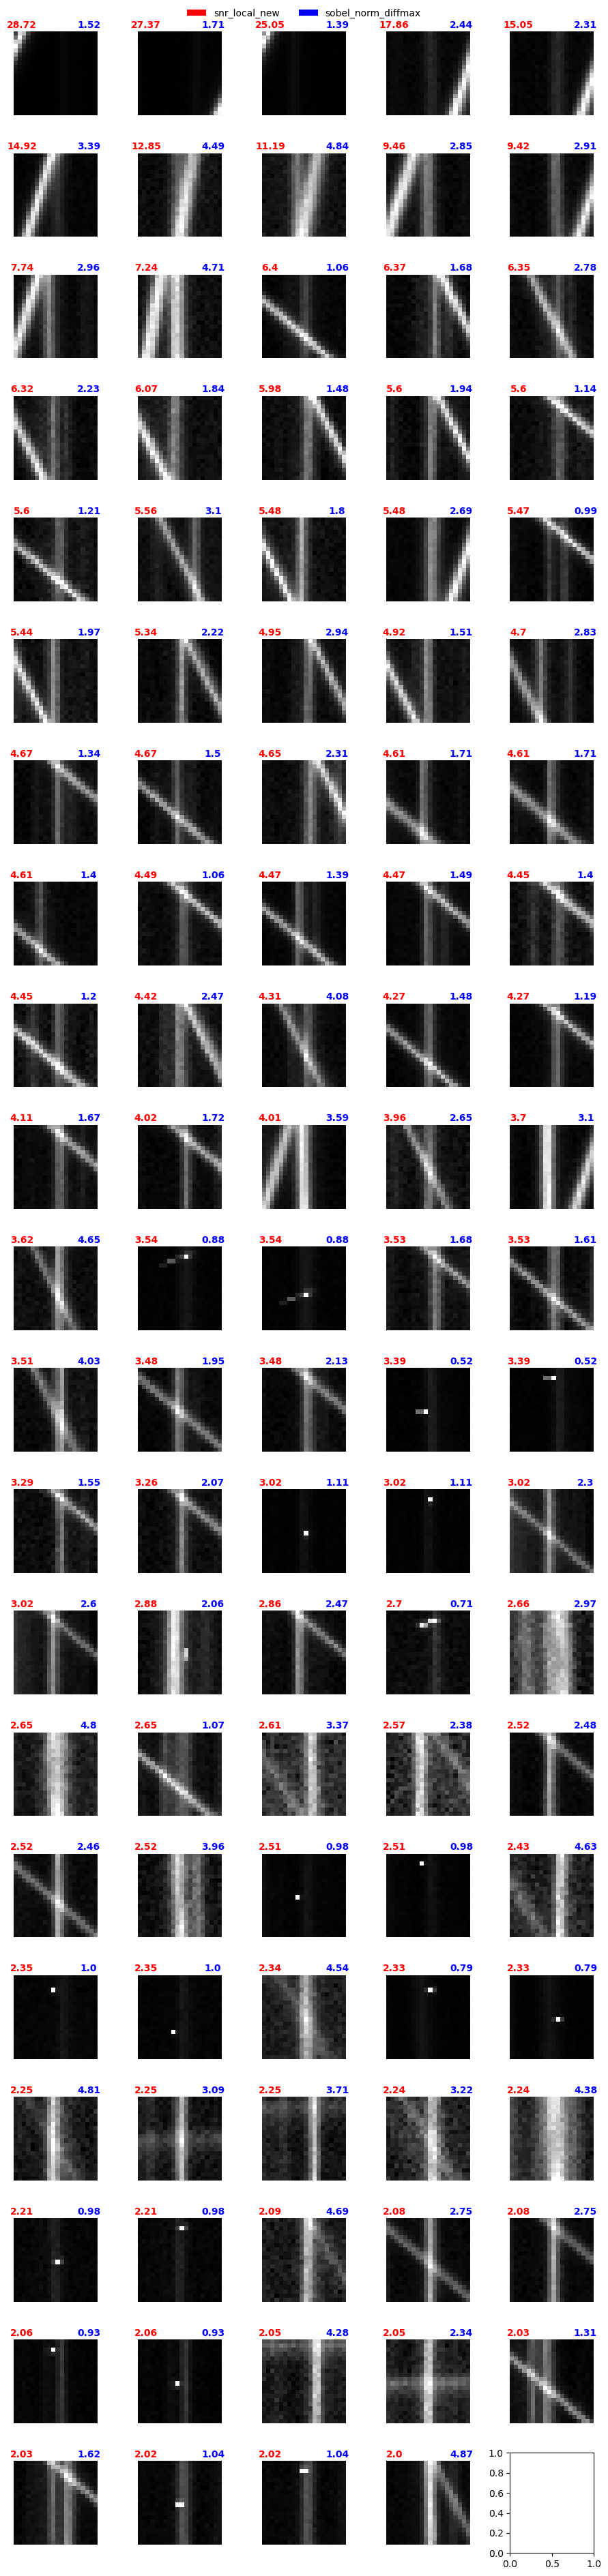

In [273]:
rff.inspect_df_w_stamp_color(df_neigh11[df_neigh11['sat_flag']==1].sort_values('snr_local_new', ascending=False) , twodec=True,titlecol=['snr_local_new', 'sobel_norm_diffmax' ])

In [266]:
df_neigh11.loc[[544557, 806862,378445,669689], 
               ["detection_size","sobel_norm_diffmax", 
                "sobel_norm_stdv_rat",
                "snr_local_new", "snr_global_new", "max_num_consecutive_new"]]

,detection_size,sobel_norm_diffmax,sobel_norm_stdv_rat,snr_local_new,snr_global_new,max_num_consecutive_new
544557,2.0,5.534854,6.702845,9.689741,9.428516,0.0
806862,7.0,7.175373,8.214600,7.502406,8.360849,0.0
378445,1.0,7.925335,9.286858,7.460364,6.610399,0.0
669689,2.0,7.804929,8.033532,6.937214,6.719194,0.0


/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020138241_000686_zi_c14_x_0023._extraction_predsarray_3_predsarray.npy


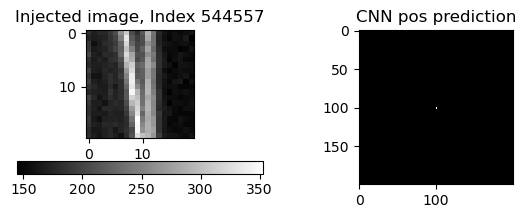

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020141806_000686_zi_c09_x_0019._extraction_predsarray_4_predsarray.npy


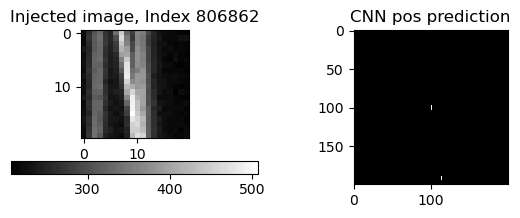

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020141806_000686_zi_c09_x_0018._extraction_predsarray_4_predsarray.npy


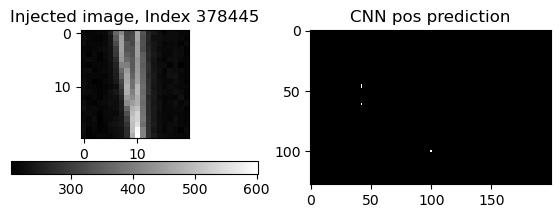

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020141806_000686_zi_c09_x_0015._extraction_predsarray_4_predsarray.npy


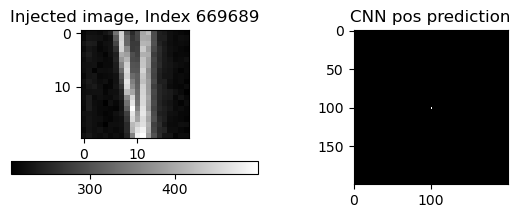

In [258]:
for index in [544557, 806862,378445,669689]:
    rff.inspect_stamp_and_map(df_nodup, index, size=100, eff=False)

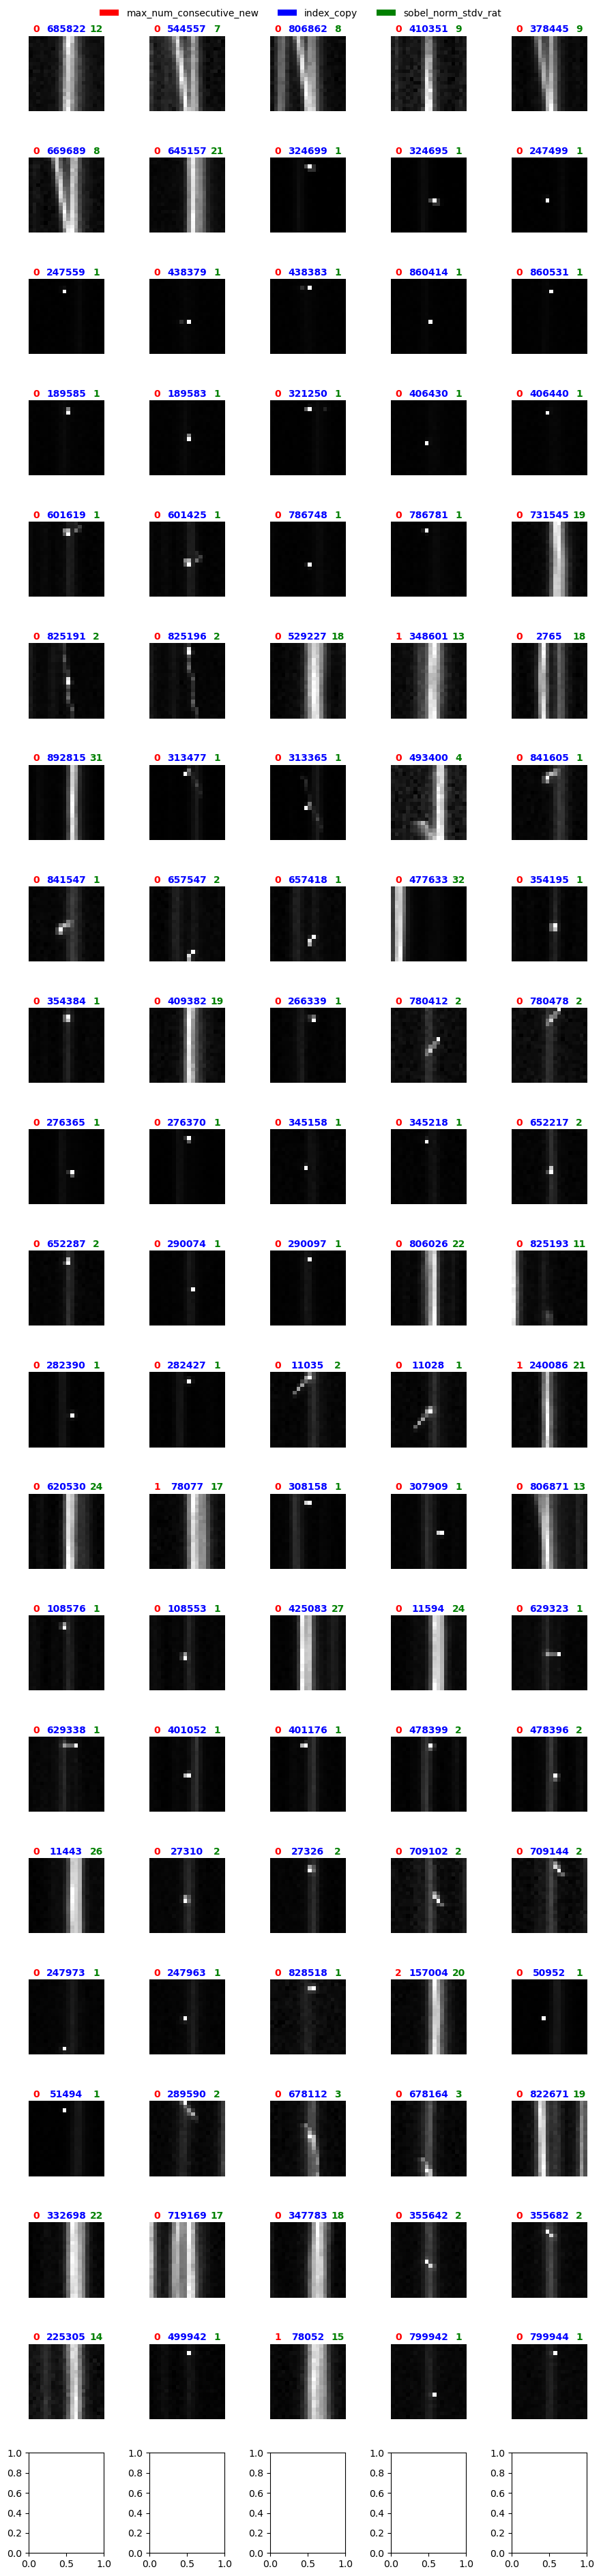

In [254]:
rff.inspect_df_w_stamp_color(nosatnocr.sort_values('snr_local_new', ascending=False)[:100] , titlecol=['max_num_consecutive_new', 'index_copy', 'sobel_norm_stdv_rat' ])

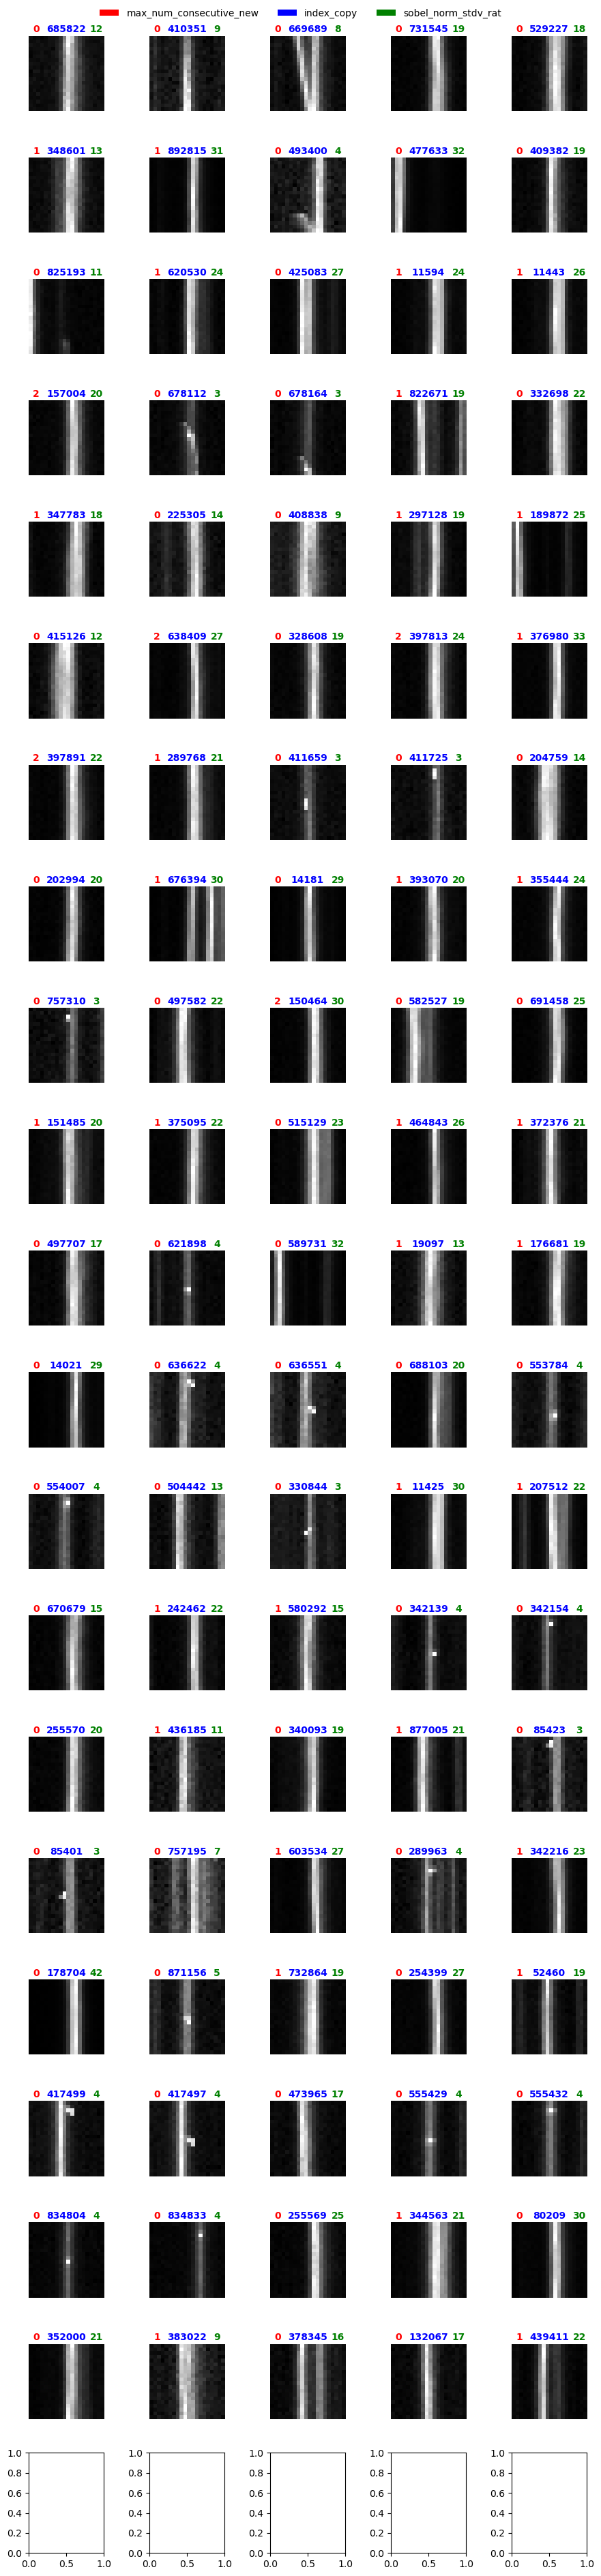

In [208]:
rff.inspect_df_w_stamp_color(nosatnocr.sort_values('snr_local_new', ascending=False)[:100] , titlecol=['max_num_consecutive_new', 'index_copy', 'sobel_norm_stdv_rat' ])

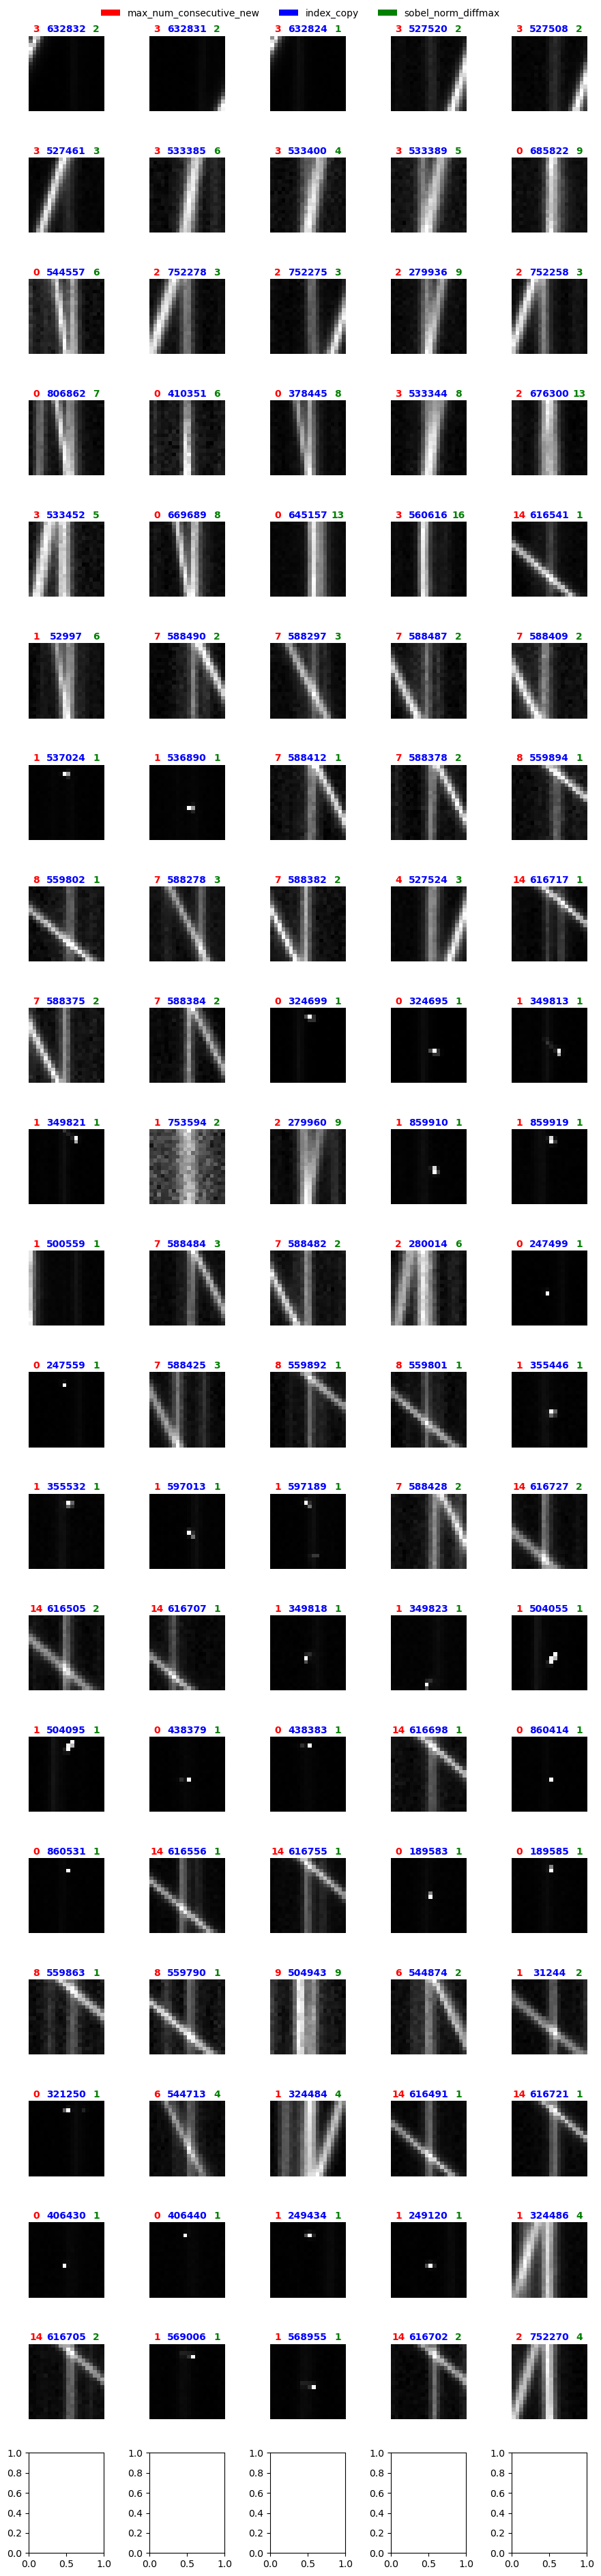

In [233]:
rff.inspect_df_w_stamp_color(subset11.sort_values('snr_local_new', ascending=False)[:100] , titlecol=['max_num_consecutive_new','index_copy', 'sobel_norm_diffmax' ])

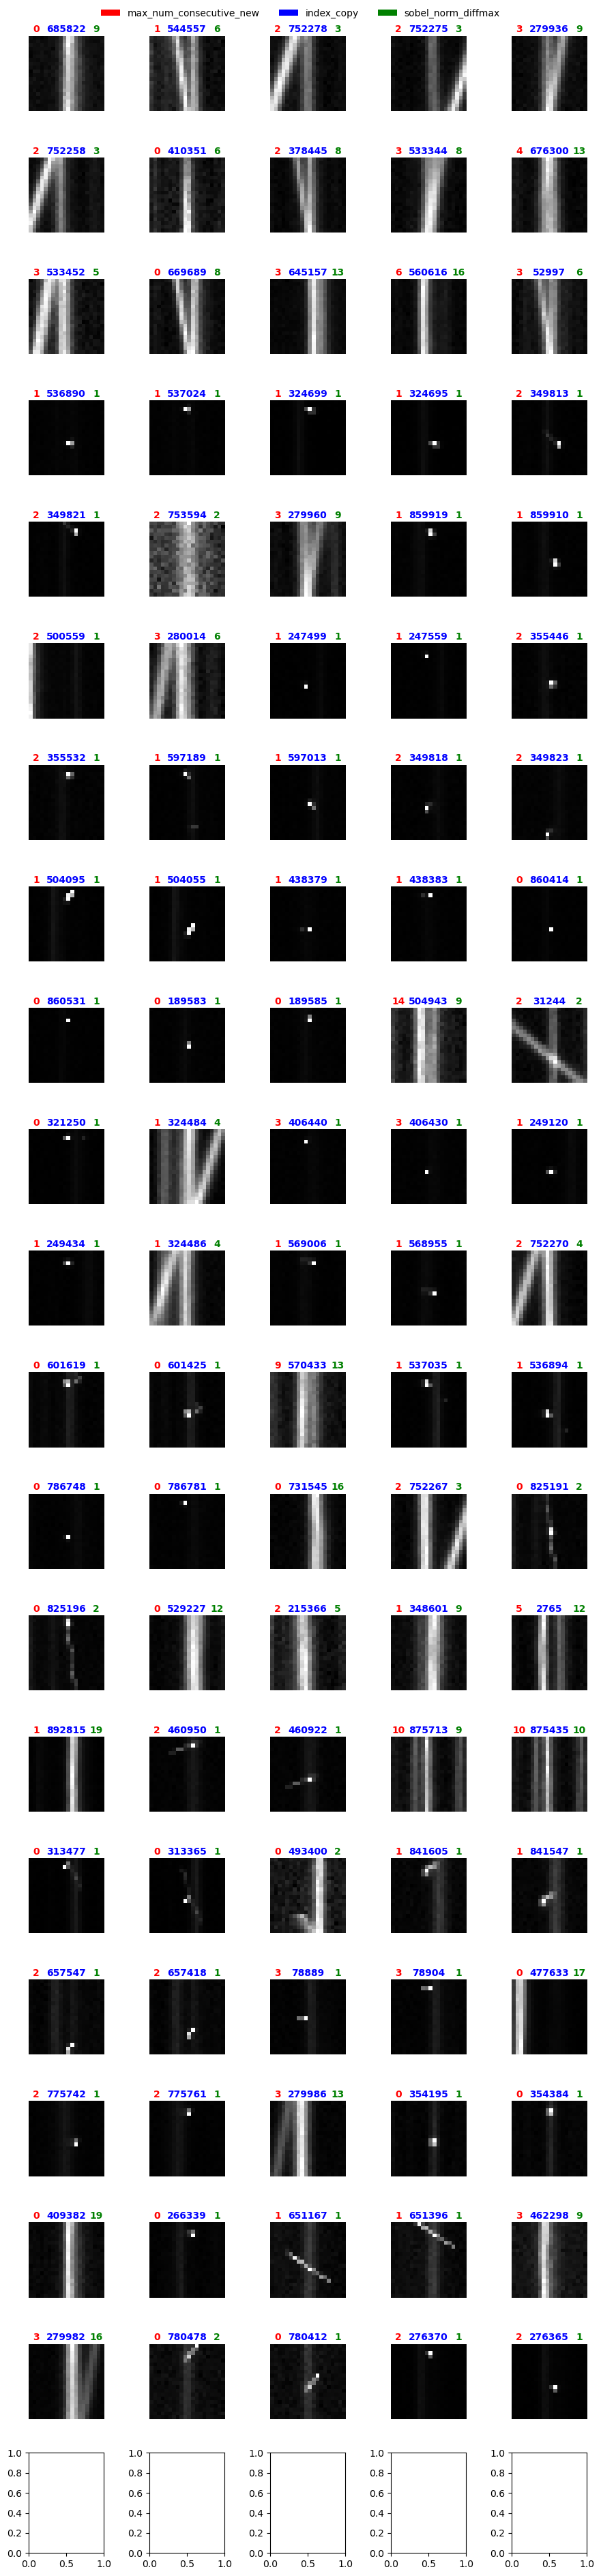

In [191]:
rff.inspect_df_w_stamp_color(maybe.sort_values('snr_local_new', ascending=False)[:100] , titlecol=['max_num_consecutive_new','index_copy', 'sobel_norm_diffmax' ])

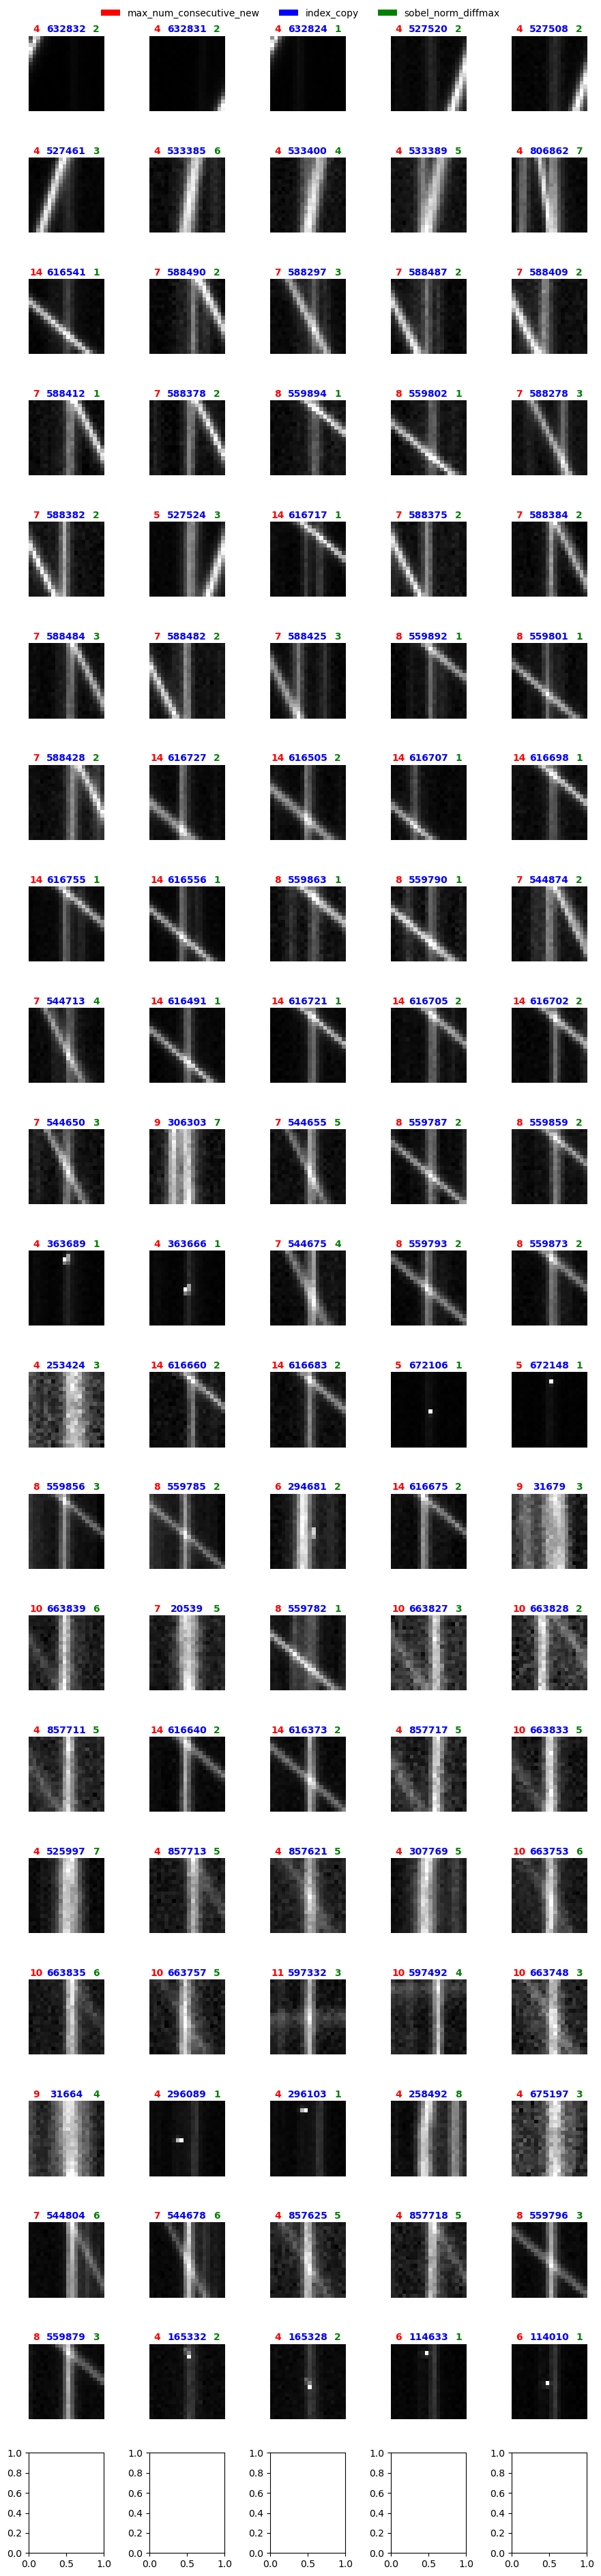

In [188]:
rff.inspect_df_w_stamp_color(subset9[(subset9['sobel_norm_diffmax']<8)*(subset9['max_num_consecutive_new']>3)][:100], titlecol=['max_num_consecutive_new','index_copy', 'sobel_norm_diffmax' ])

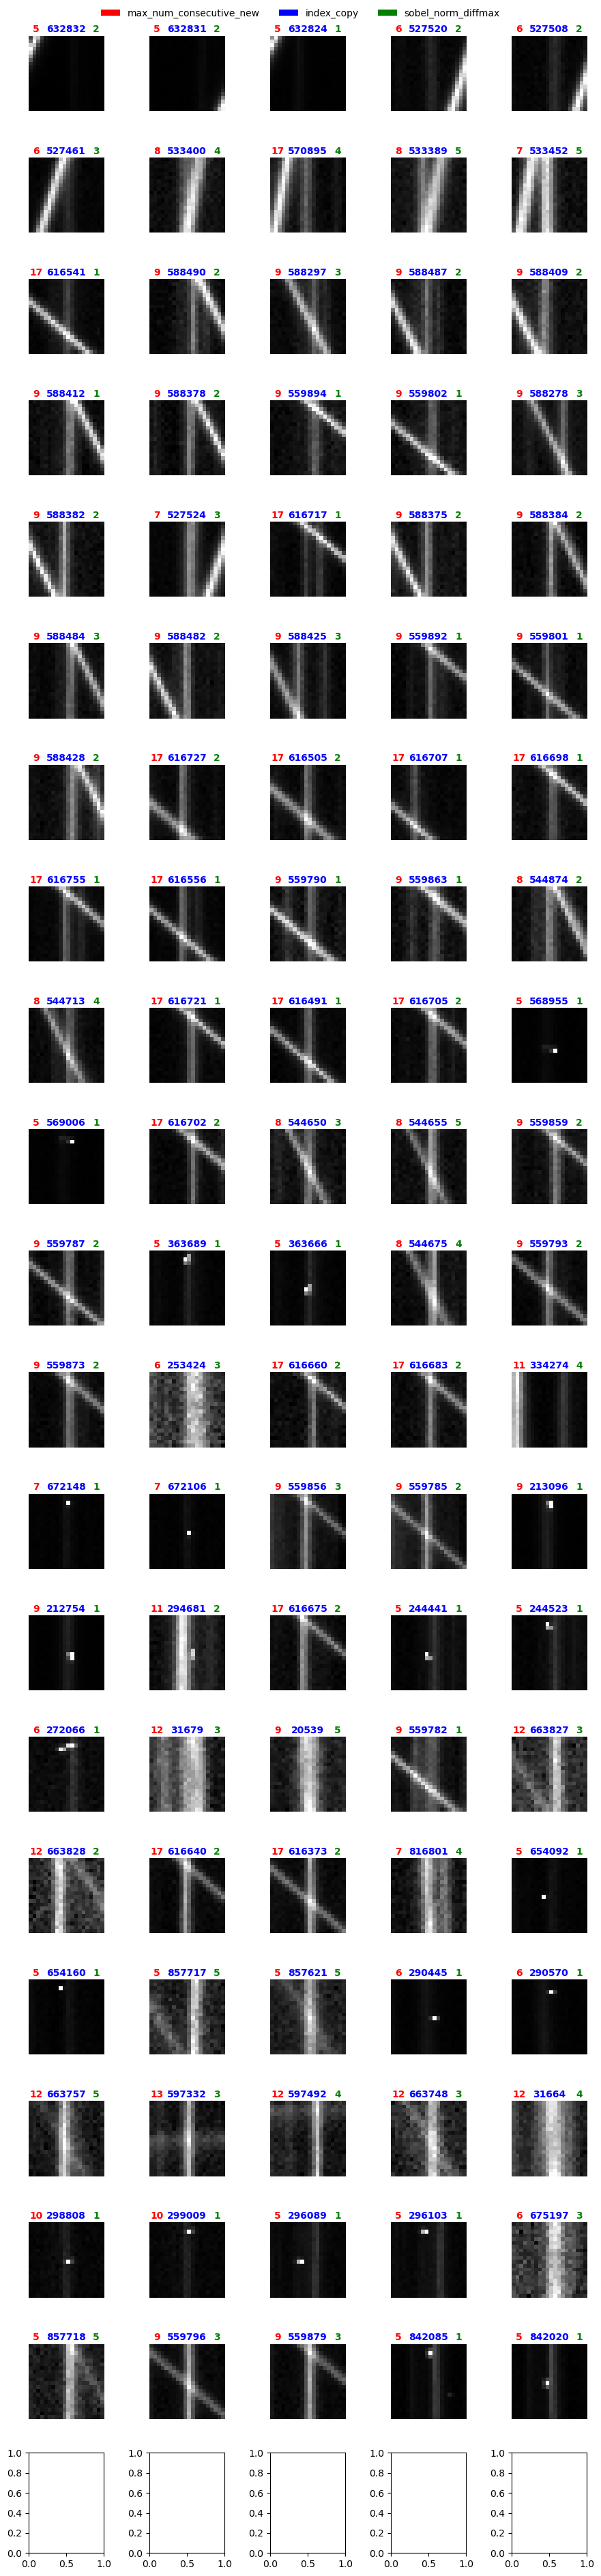

In [154]:
rff.inspect_df_w_stamp_color(subset4[(subset4['sobel_norm_diffmax']<5)*(subset4['max_num_consecutive_new']>4)][:100], titlecol=['max_num_consecutive_new','index_copy', 'sobel_norm_diffmax' ])

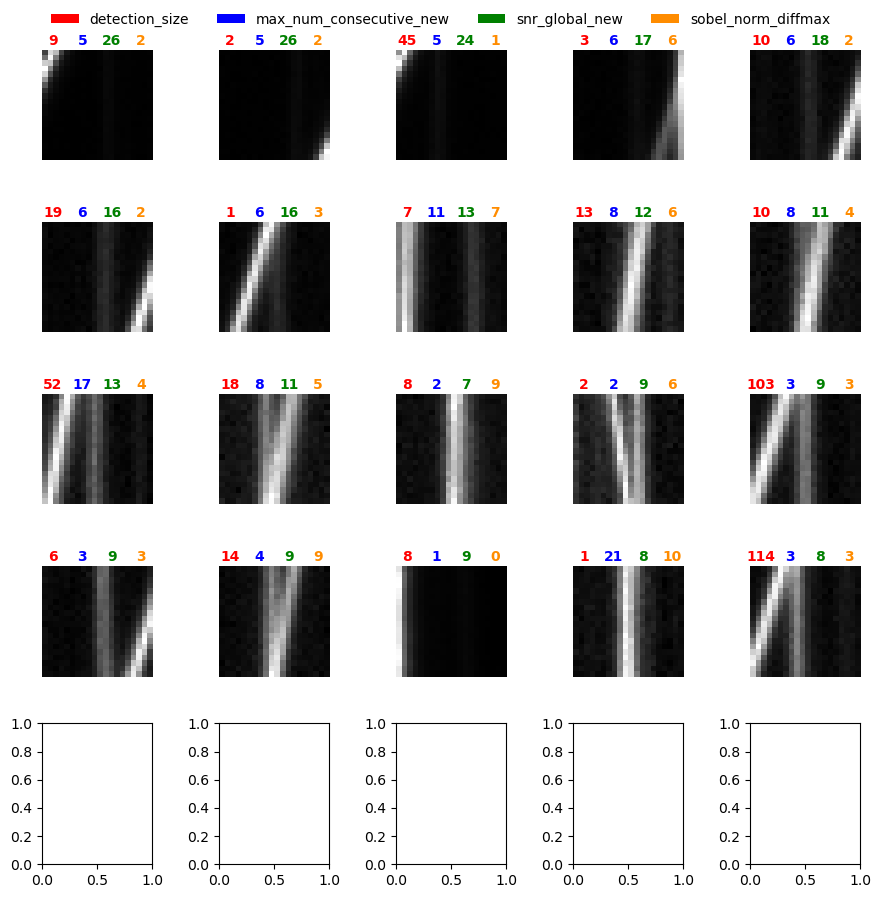

In [153]:
rff.inspect_df_w_stamp_color(subset8.sort_values('snr_local_new',ascending=False)[:20], titlecol=['detection_size','max_num_consecutive_new','snr_global_new', 'sobel_norm_diffmax' ])

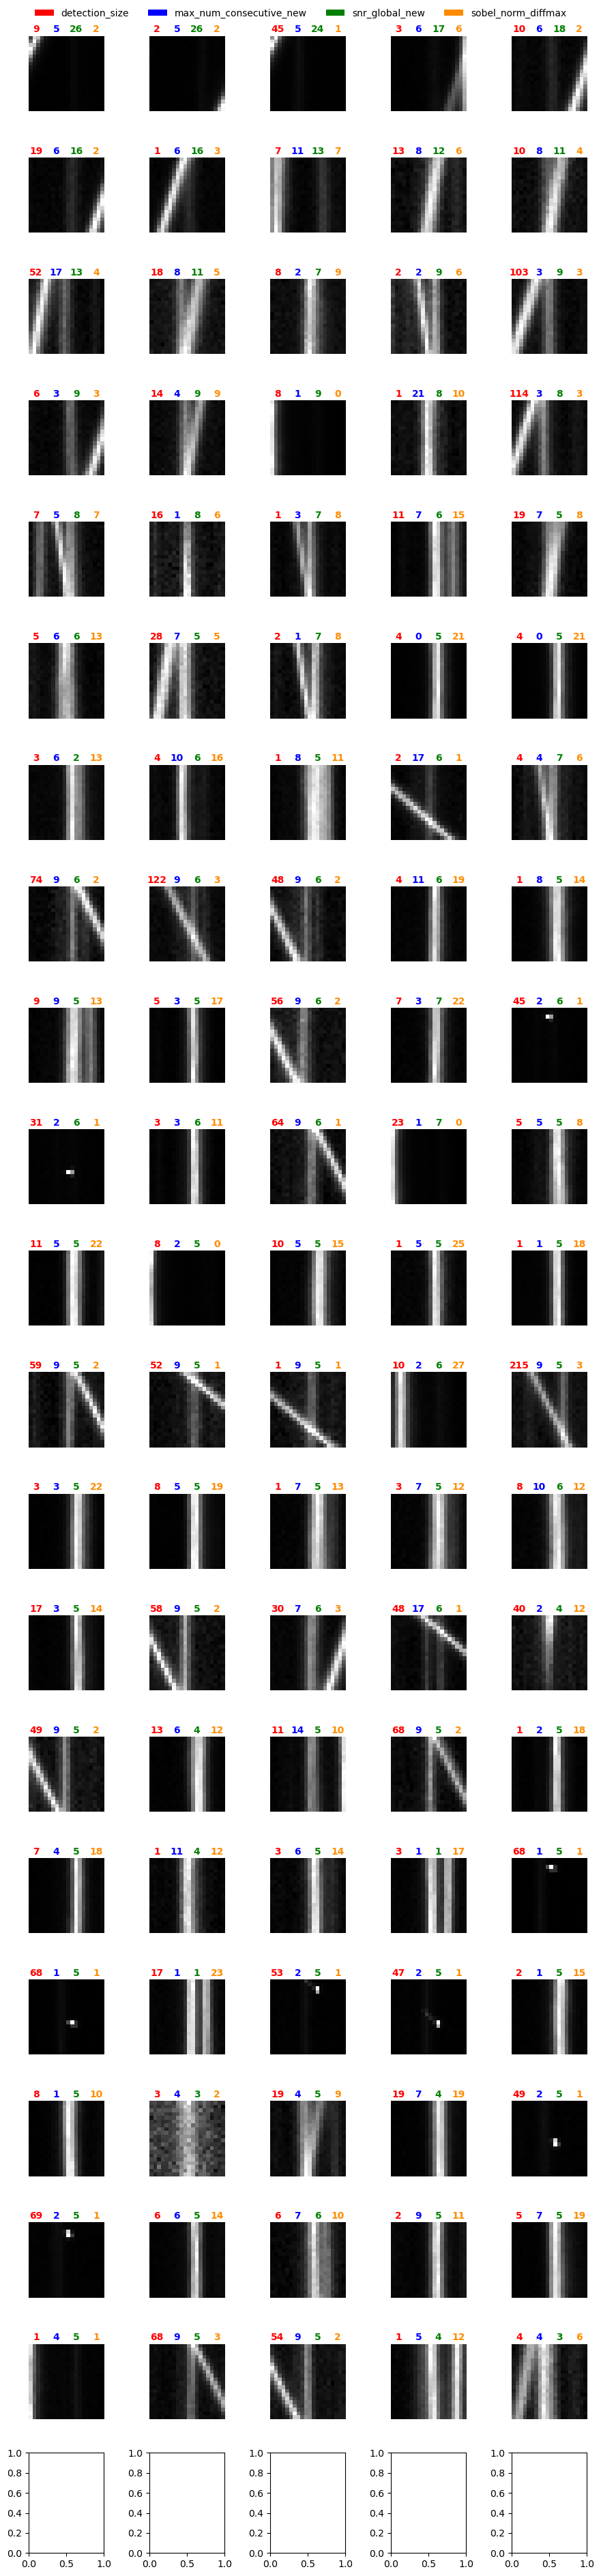

In [146]:
rff.inspect_df_w_stamp_color(subset4.sort_values('snr_local_new',ascending=False)[:100], titlecol=['detection_size','max_num_consecutive_new','snr_global_new', 'sobel_norm_diffmax' ])

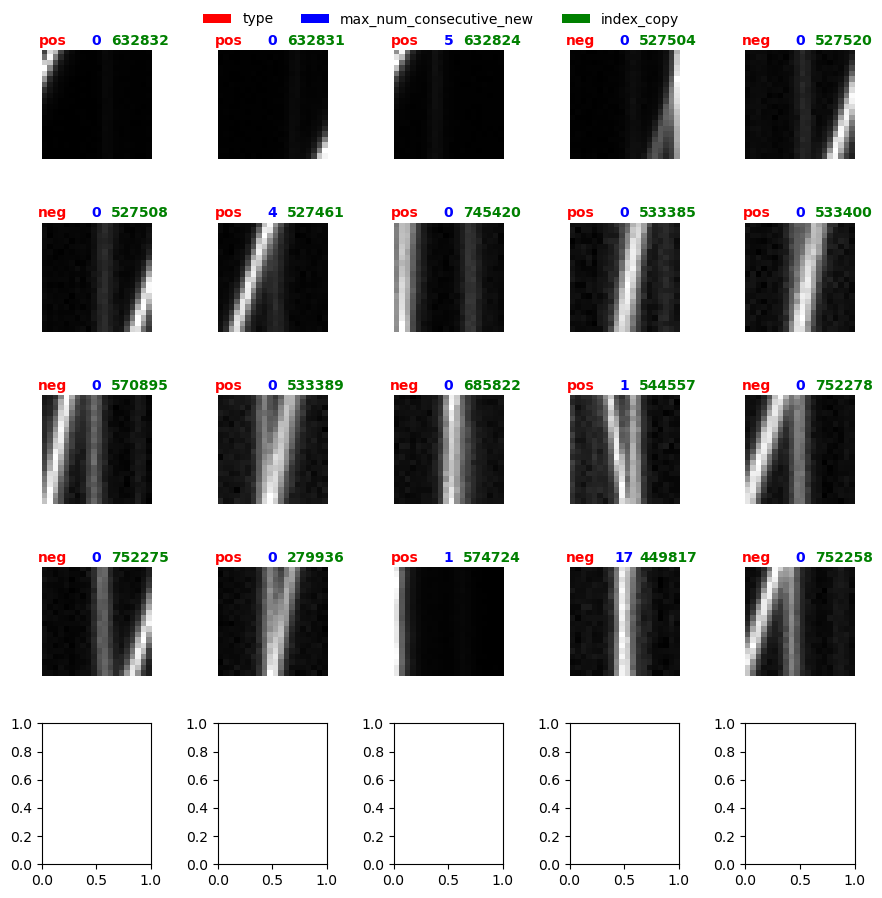

In [107]:
rff.inspect_df_w_stamp_color(subset5.sort_values('snr_local_new',ascending=False)[:20], titlecol=['type','max_num_consecutive_new','index_copy' ])

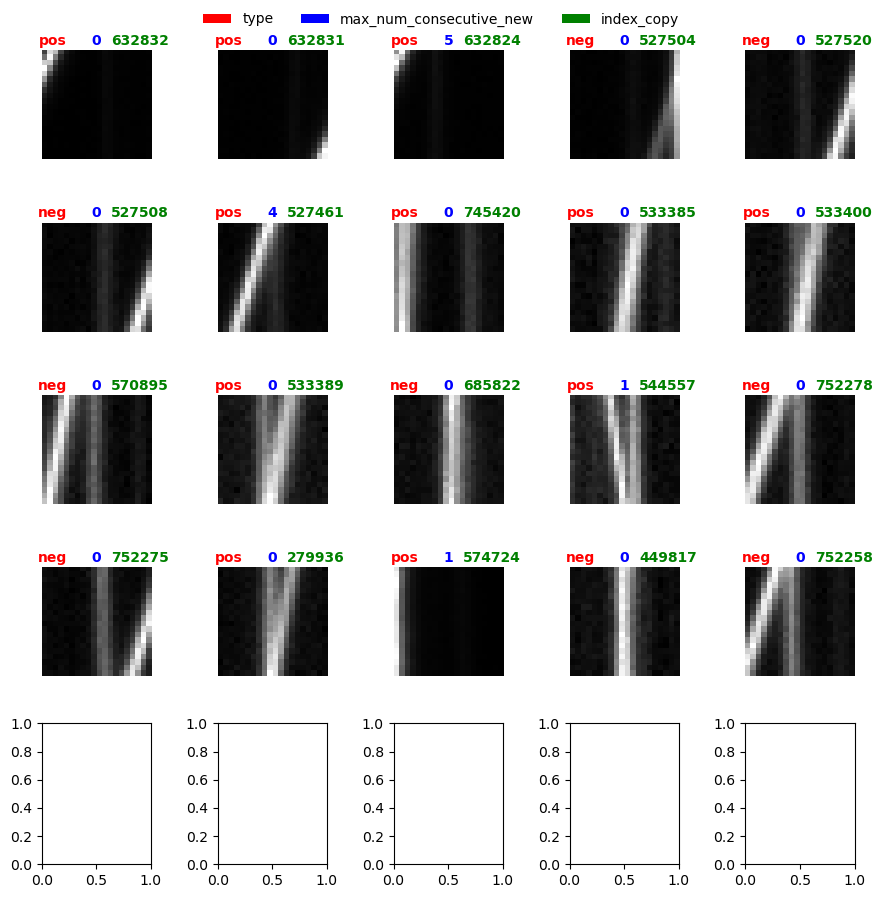

In [111]:
rff.inspect_df_w_stamp_color(subset6.sort_values('snr_local_new',ascending=False)[:20], titlecol=['type','max_num_consecutive_new','index_copy' ])

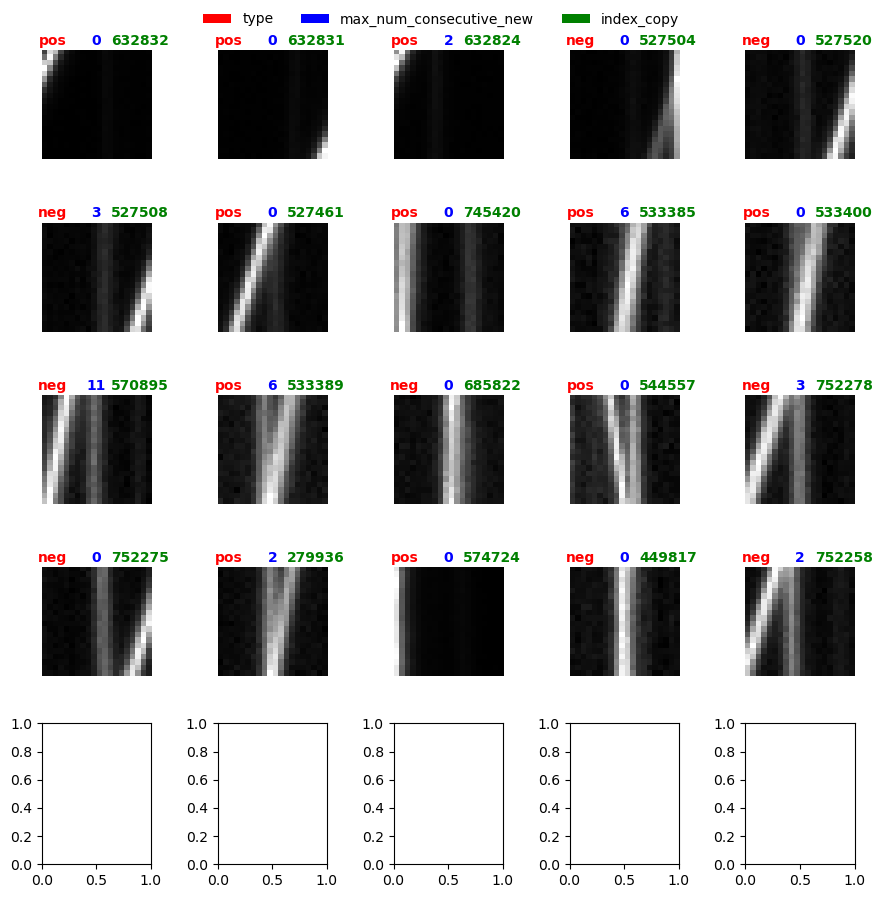

In [125]:
rff.inspect_df_w_stamp_color(subset7.sort_values('snr_local_new',ascending=False)[:20], titlecol=['type','max_num_consecutive_new','index_copy' ])

In [ ]:
'''
counting

not clearly satellites
3+2+1+1+3+3

cosmic rays
8+12+8+13+15+17

not clearly satellites but are double streaks that i imagine will get dropped
4+2+2+4

out of 175
'''

In [226]:
df_neigh.loc[559785, "snr_local_new"]

3.0161686651101967

In [225]:
df_neigh[df_neigh["sat_flag"]==1][137:144]

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local,...,num_in_file_in_star,index_copy,num_in_file_new,num_consecutive_up_new,num_consecutive_down_new,possible_up_indices_new,possible_down_indices_new,max_num_consecutive_new,sat_flag,sat_neighbor
559856,ztf_20221020154120_000640_zi_c08_x_0014.,1,neg,2043.600000,79.125000,40.0,87.0,2910.0,2.125000,0.160706,...,6.0,559856,17.0,15.0,0.0,"[559782, 559787, 559790, 559793, 559796, 55979...",[],8.0,1.0,0.0
559785,ztf_20221020154120_000640_zi_c08_x_0014.,1,pos,2034.476190,79.071429,42.0,87.0,2910.0,2.071429,2.780341,...,6.0,559785,17.0,15.0,0.0,"[559782, 559787, 559790, 559793, 559796, 55979...",[],8.0,1.0,0.0
806026,ztf_20221020157697_000640_zi_c04_x_0022.,2,neg,1185.375000,1626.625000,8.0,1636.0,114.0,0.625000,1.017777,...,9.0,806026,16.0,4.0,5.0,"[806013, 806014, 806035, 806036]","[805998, 805999, 806000, 806002, 806015]",2.0,1.0,0.0
282427,ztf_20221020157697_000640_zi_c07_x_0025.,2,neg,2444.051724,1917.344828,58.0,1924.0,1143.0,3.344828,0.439997,...,3.0,282427,4.0,0.0,2.0,[],"[282384, 282396]",1.0,1.0,0.0
282390,ztf_20221020157697_000640_zi_c07_x_0025.,2,pos,2435.860465,1916.209302,43.0,1924.0,1143.0,2.209302,0.503972,...,3.0,282390,4.0,0.0,2.0,[],"[282384, 282396]",1.0,1.0,0.0
213096,ztf_20221020163819_000640_zg_c02_x_0015.,3,neg,1146.584615,2146.430769,65.0,2154.0,1174.0,2.430769,0.255261,...,3.0,213096,3.0,1.0,0.0,[212687],[],1.0,1.0,0.0
212754,ztf_20221020163819_000640_zg_c02_x_0015.,3,pos,1138.544118,2145.911765,68.0,2154.0,1174.0,1.911765,3.182379,...,3.0,212754,3.0,1.0,0.0,[212687],[],1.0,1.0,0.0


In [227]:
sats = df_neigh[df_neigh["sat_flag"]==1]
sats = sats[sats['snr_local_new']>2]

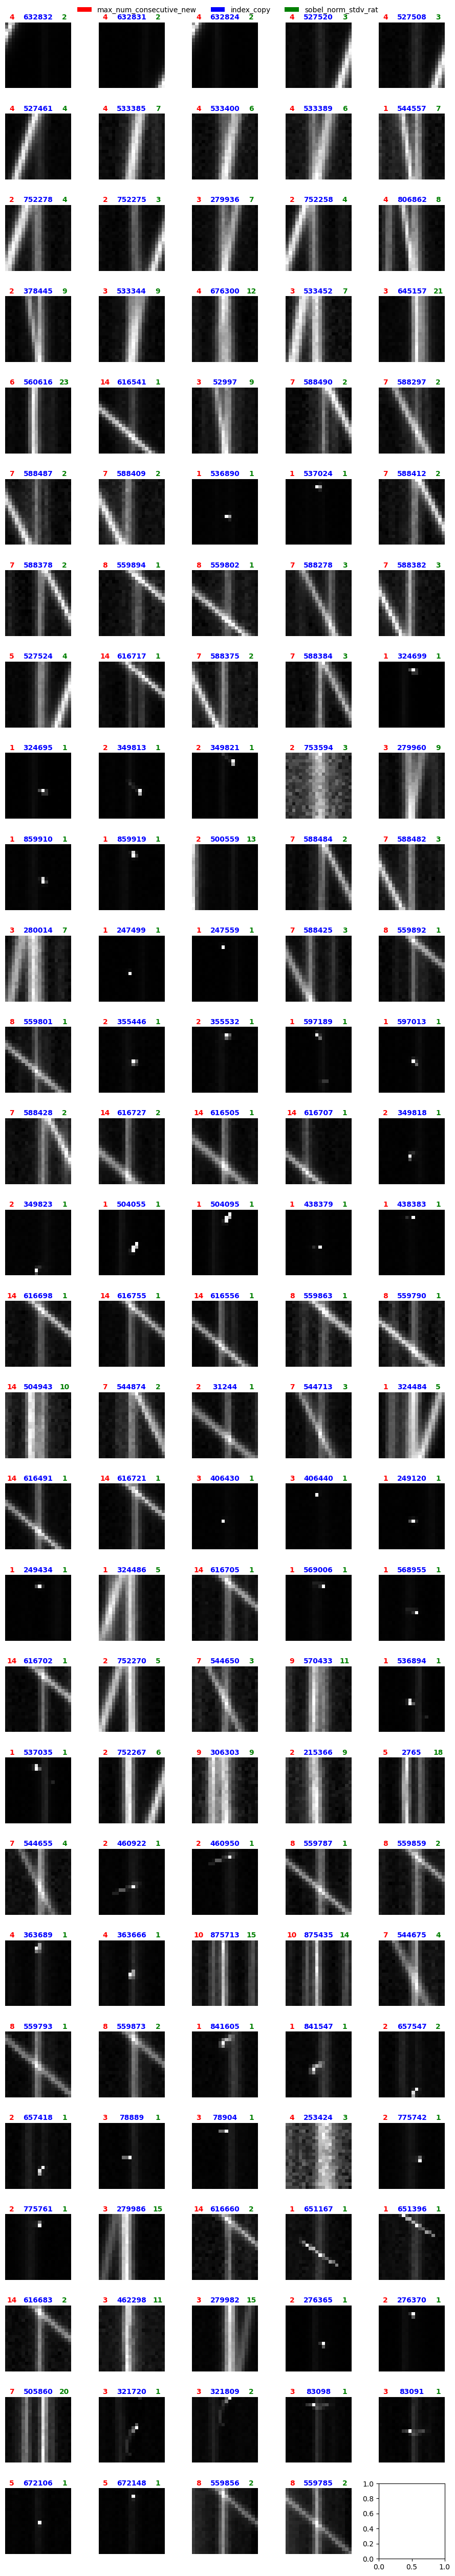

In [228]:
rff.inspect_df_w_stamp_color(sats, titlecol=['max_num_consecutive_new', 'index_copy', 'sobel_norm_stdv_rat' ])

In [288]:
crs = df_neigh[((df_neigh["sobel_norm_stdv_rat"]<3) |(df_neigh['sobel_norm_diffmax']<2))]
# crs = crs[crs['sobel_norm_diffmax']<2]
crs = crs[crs['sat_flag']==0]

In [302]:
len(df_nodup[((df_nodup["sobel_norm_stdv_rat"]<3) |(df_nodup['sobel_norm_diffmax']<2))])

34001

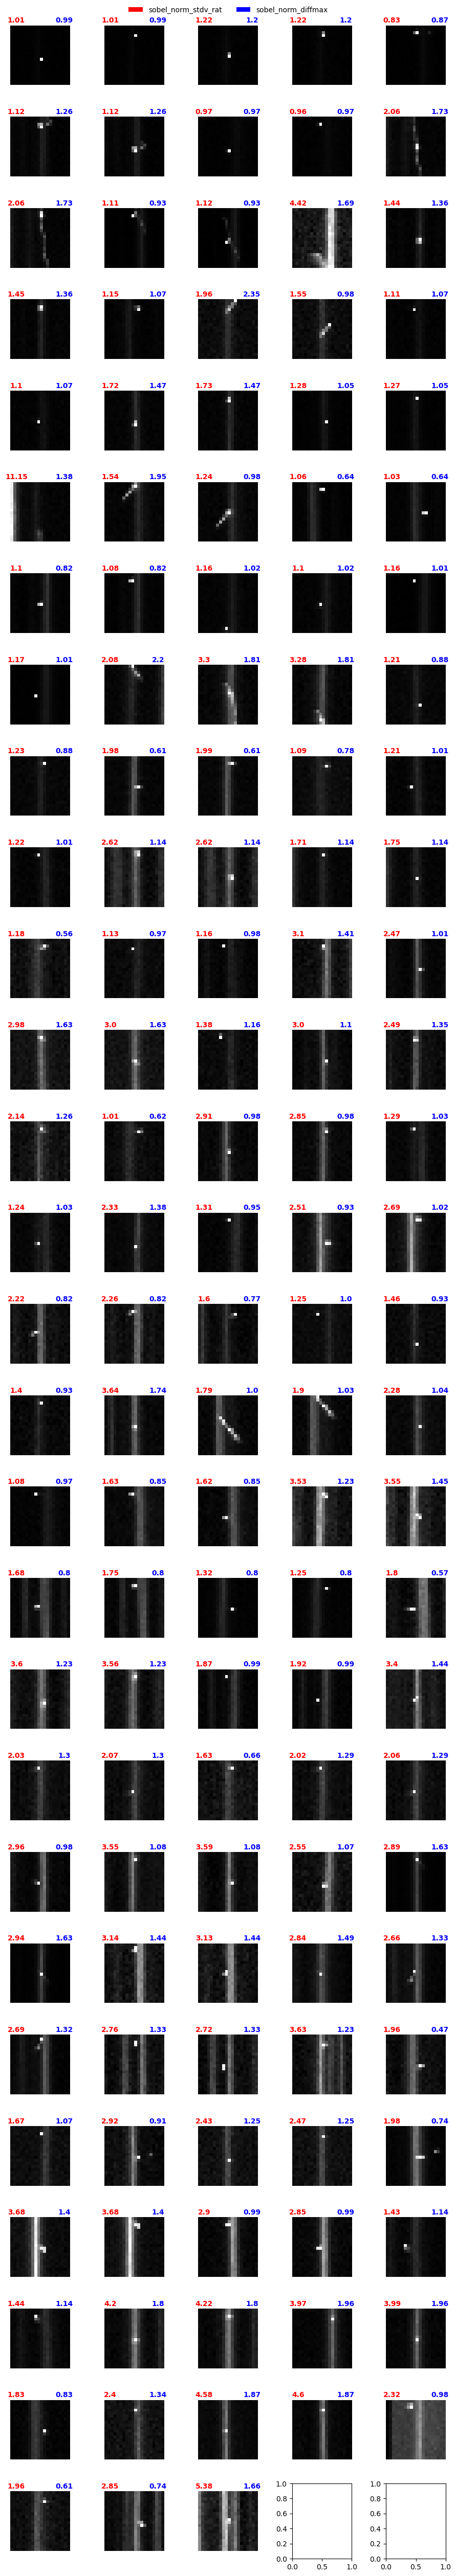

In [290]:
rff.inspect_df_w_stamp_color(crs.sort_values('snr_local_new', ascending=False), twodec=True,titlecol=['sobel_norm_stdv_rat', 'sobel_norm_diffmax' ])

In [295]:
len(df_neigh11)

1000

In [299]:
len(df_neigh11[df_neigh11['sat_flag']==0])

896

In [320]:
nosatnocr11 = df_neigh11[df_neigh11['sat_flag']==0]
nosatnocr11 = nosatnocr11[nosatnocr11['sobel_norm_stdv_rat']>3]
# nosatnocr11 = nosatnocr11[nosatnocr11['sobel_norm_diffmax']>2]
nosatnocr11 = nosatnocr11[nosatnocr11['detection_size']>1]

In [318]:
len(nosatnocr11)

361

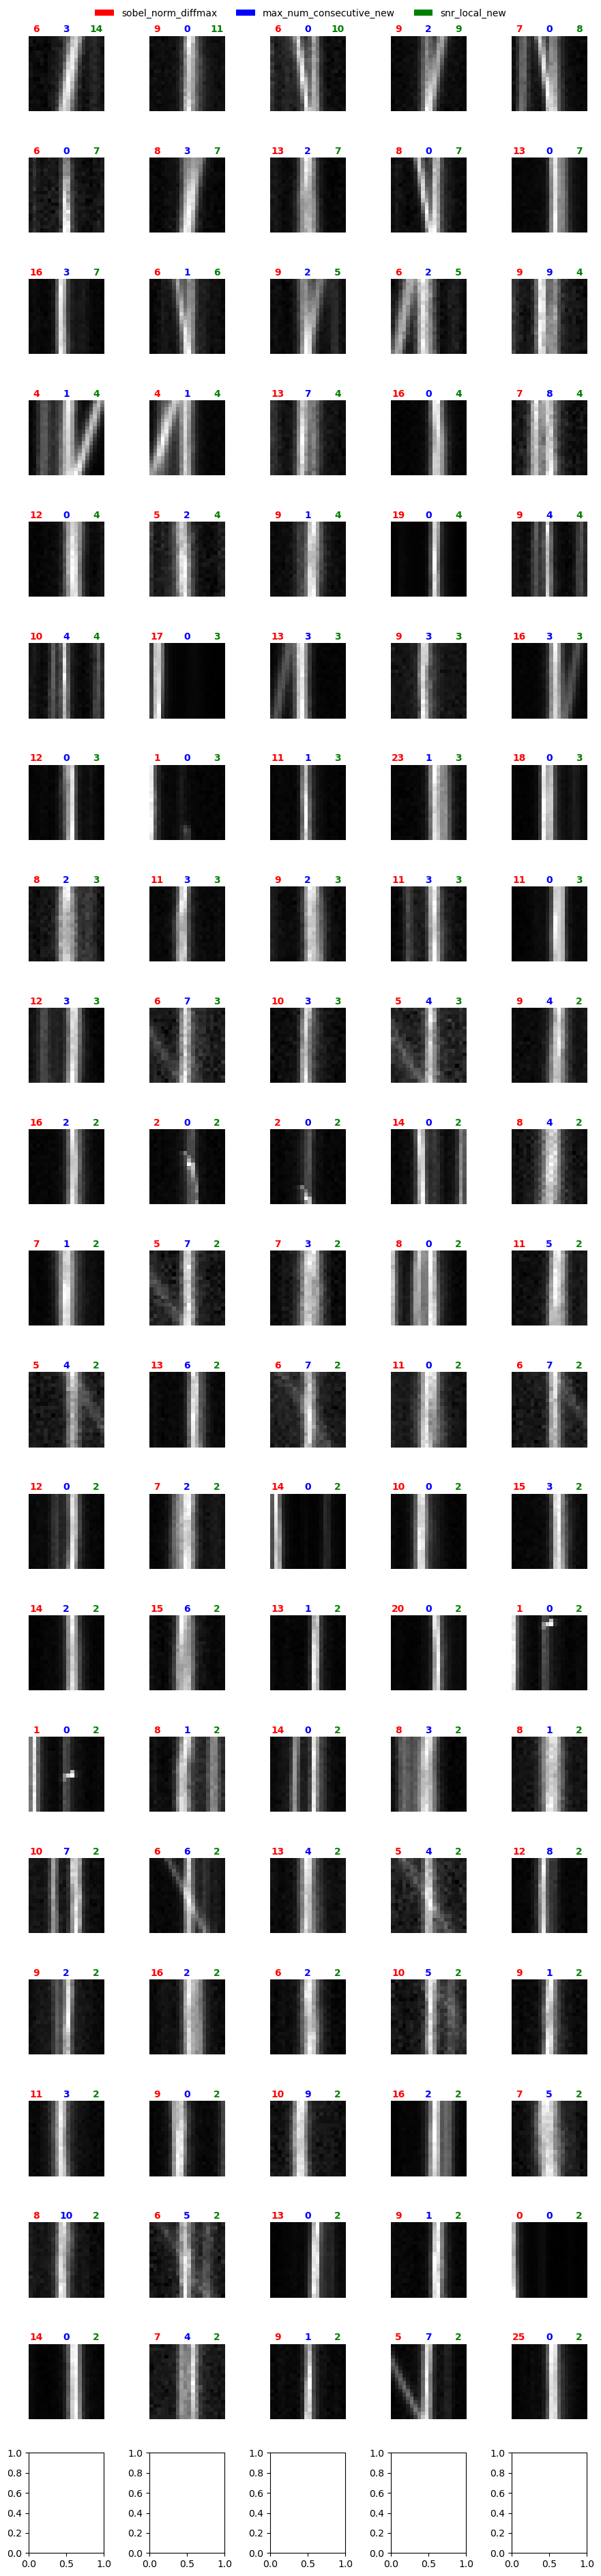

In [321]:
rff.inspect_df_w_stamp_color(nosatnocr11.sort_values('snr_local_new', ascending=False)[:100], twodec=False, titlecol=['sobel_norm_diffmax', 'max_num_consecutive_new','snr_local_new' ])

In [310]:
len(df_nodup[((df_nodup["sobel_norm_stdv_rat"]<3) |(df_nodup['sobel_norm_diffmax']<2))])

34001

In [313]:
len(df_nodup[(df_nodup["sobel_norm_stdv_rat"]<3)])

1012

In [ ]:
df_neigh11[df_neigh11['sat_flag']==0]
nosatnocr11 = nosatnocr11[nosatnocr11['sobel_norm_stdv_rat']>3]

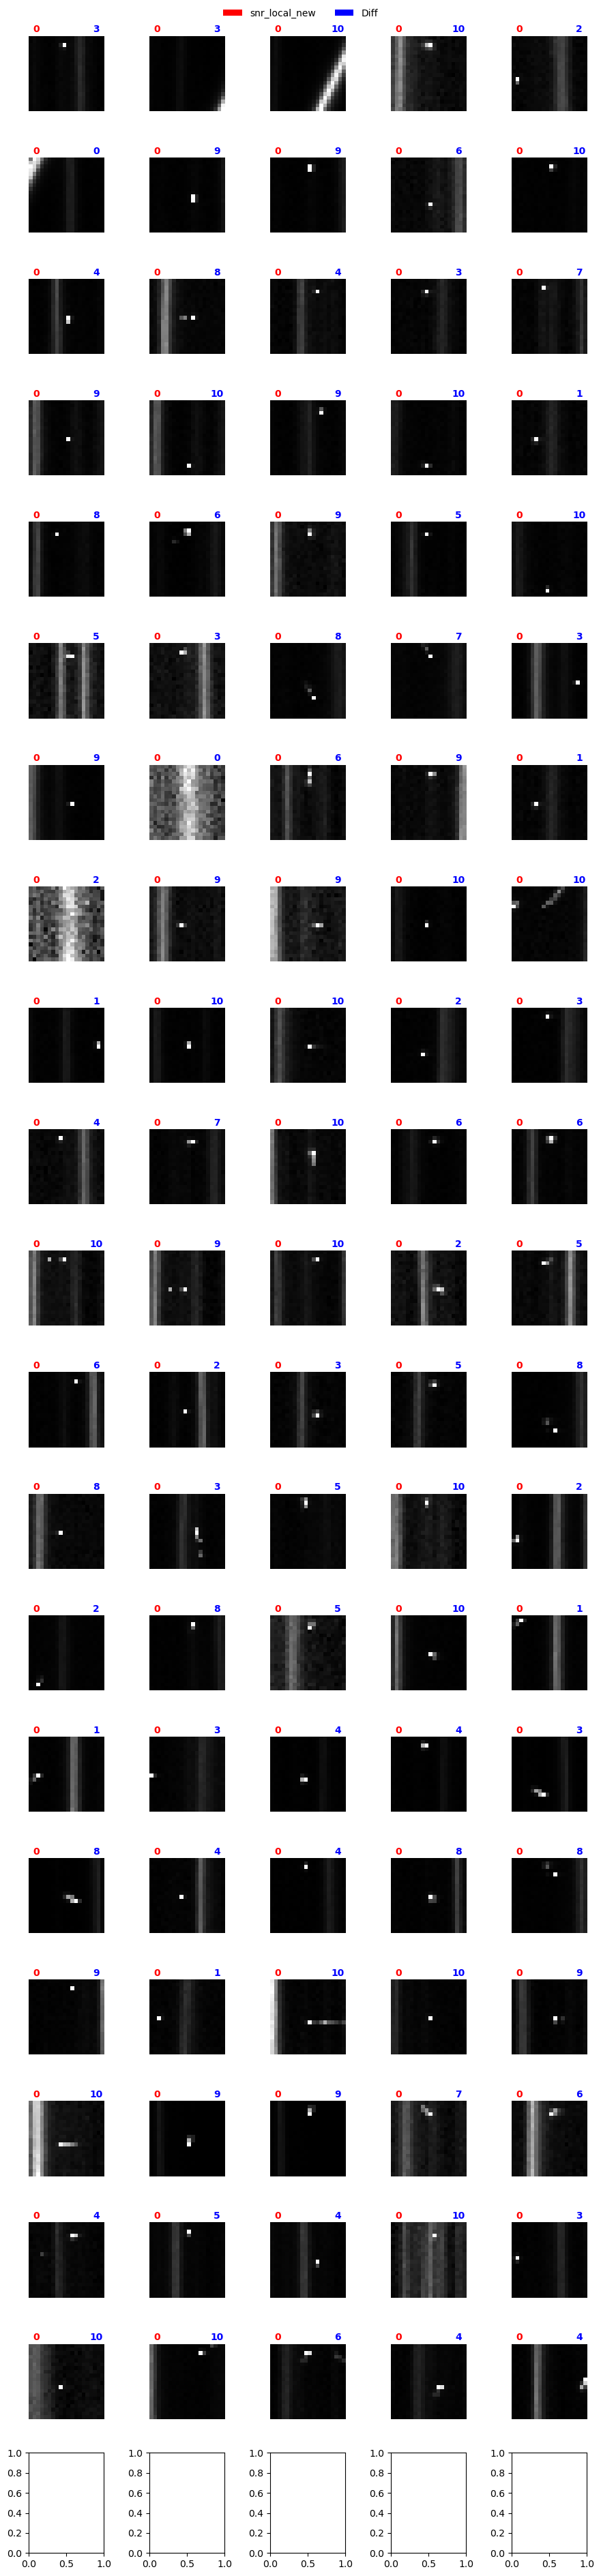

In [322]:
rff.inspect_df_w_stamp_color(df_nodup[(df_nodup["sobel_norm_stdv_rat"]<3)].sort_values('snr_local_new', ascending=False)[-100:], titlecol=['snr_local_new', 'Diff'])

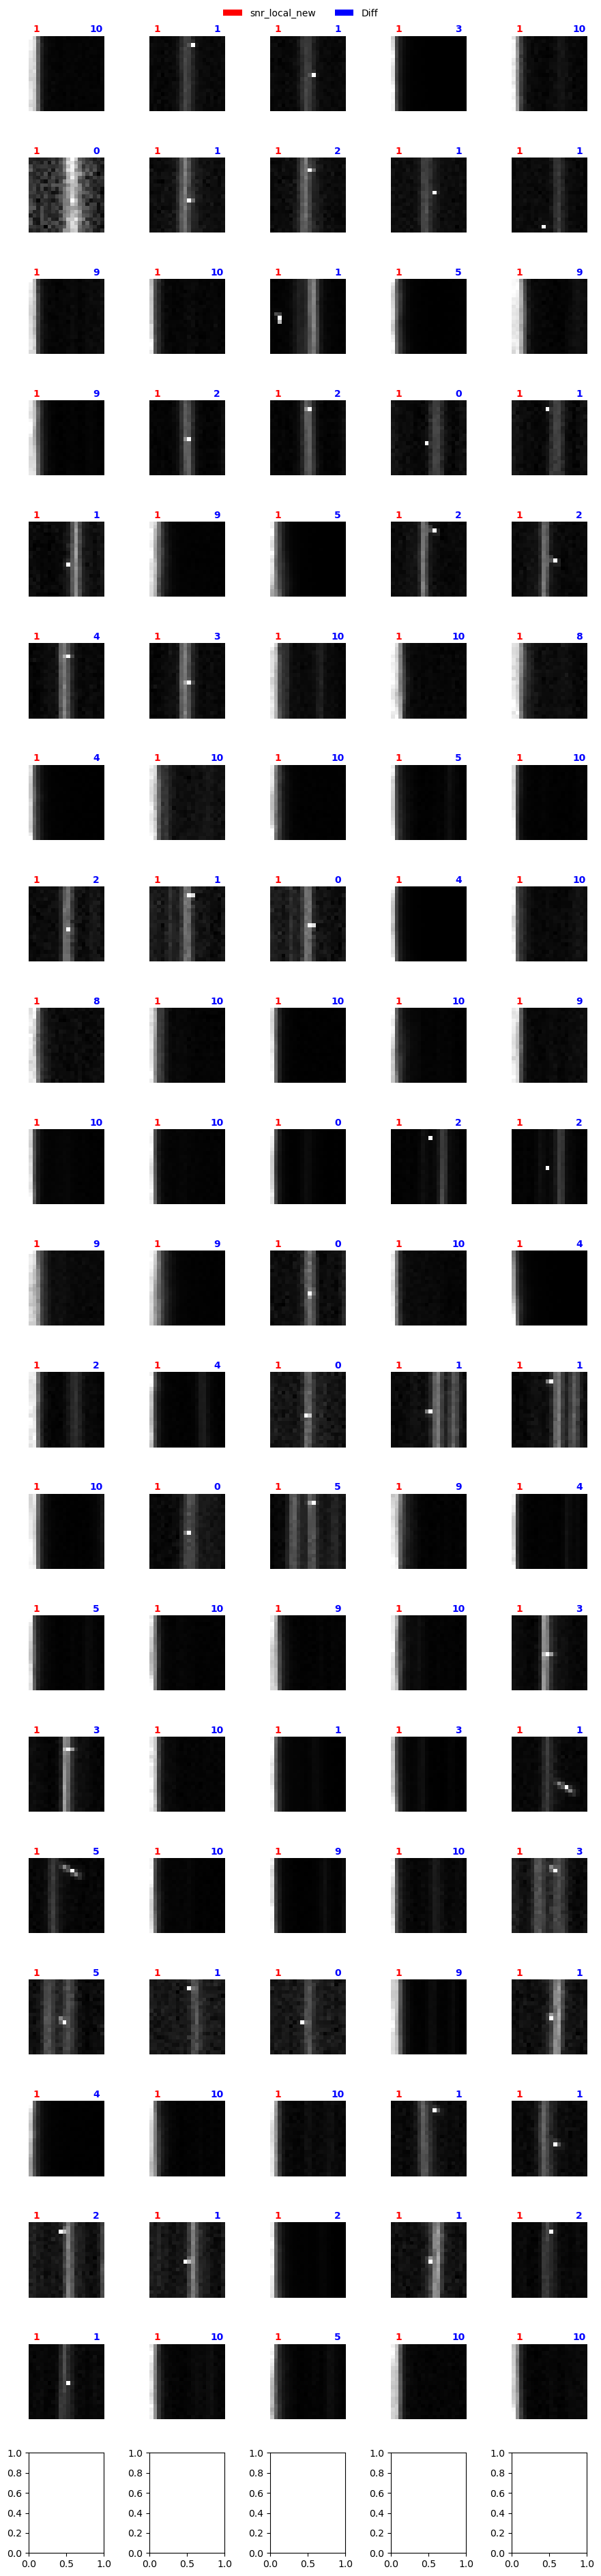

In [311]:
rff.inspect_df_w_stamp_color(df_nodup[((df_nodup["sobel_norm_stdv_rat"]<3) |(df_nodup['sobel_norm_diffmax']<2))].sort_values('snr_local_new', ascending=False)[1000:1100], titlecol=['snr_local_new', 'Diff'])

In [12]:
def get_real_cands(df, detsizelim=1, usesatflag=True, usesatneighbor=True, crstdvlim=3, diff=5, maxnuminstar=0):
    df = df.copy()
    df = df[df["is_smaller_dup"]==0]
    df = df[df['detection_size']>detsizelim]
    if usesatflag==True:
        df = df[df['sat_flag']==False]
    if usesatneighbor==True:
        df = df[df['sat_neighbor']==False]
        
    df = df[df['sobel_norm_stdv_rat']>crstdvlim]
    if maxnuminstar>0:
        df = df[df['num_in_file_in_star']<maxnuminstar]
    df = df[df['Diff']<=diff]
    return df
                       #df = df[df[
    

In [4]:
df_2=pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_sats2")

In [10]:
df_1 = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_sats")

In [6]:
np.sum(df_2['sat_neighbor'])

232.0

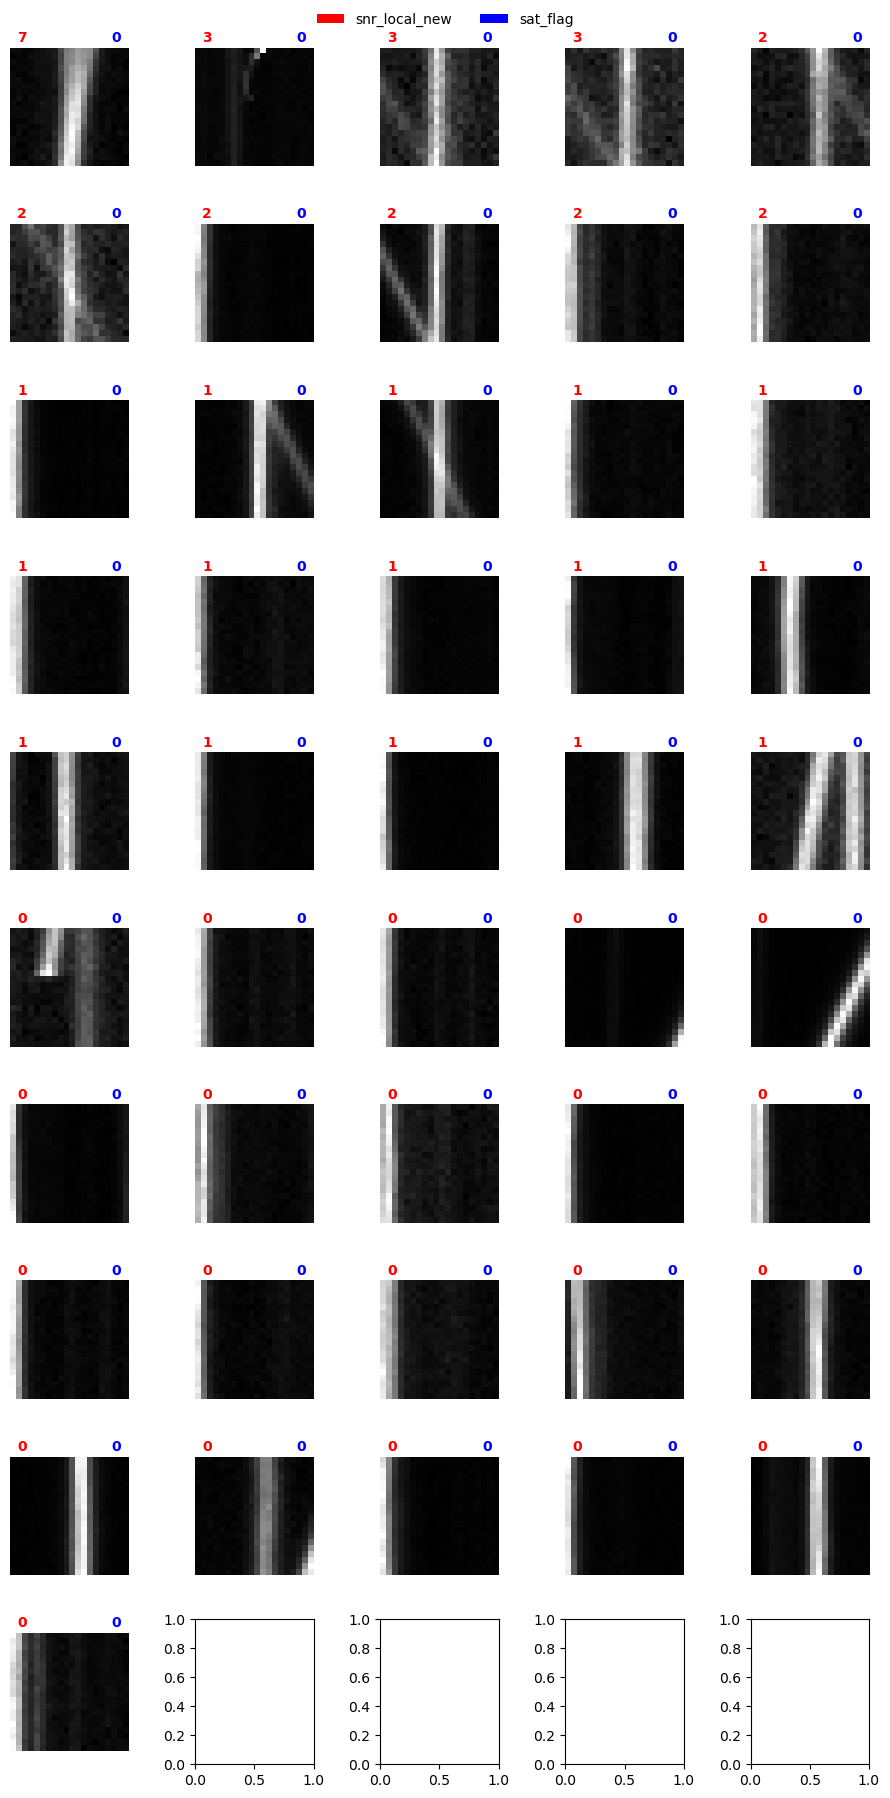

In [21]:
rff.inspect_df_w_stamp_color(df_2[(df_2['sat_neighbor']==True) & (df_2['sat_flag']==False)].sort_values('snr_local_new', ascending=False)[:50], titlecol=['snr_local_new', 'sat_flag'])

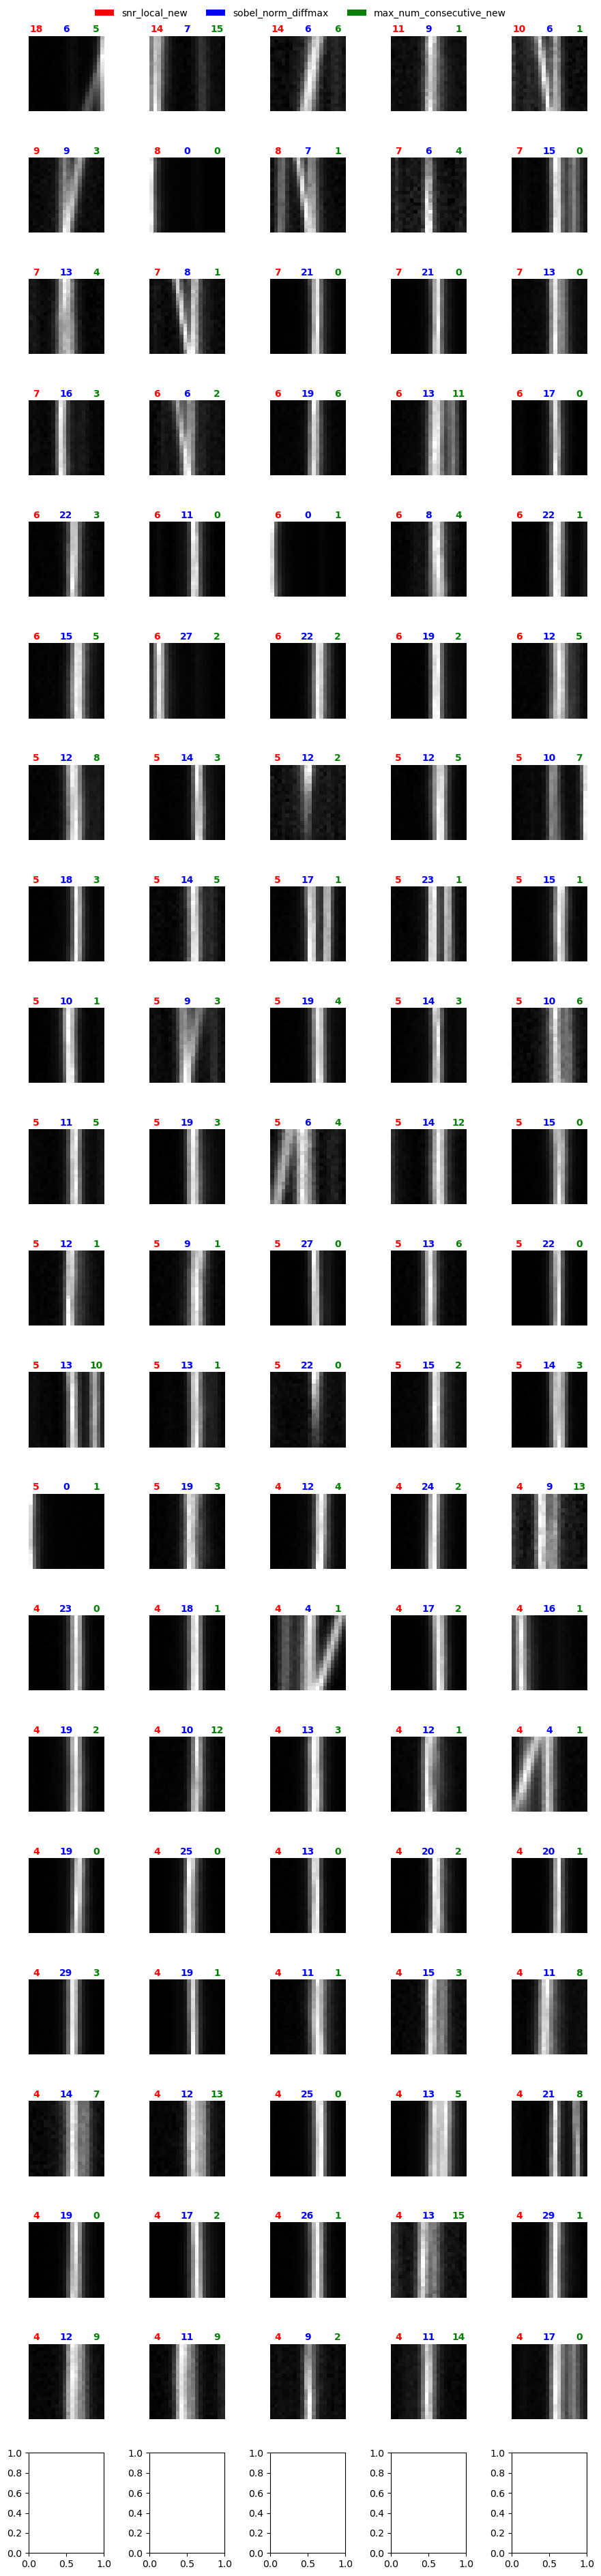

In [37]:
rff.inspect_df_w_stamp_color(get_real_cands(df_1).sort_values('snr_local_new', ascending=False)[:100], titlecol=['snr_local_new', 'sobel_norm_diffmax','max_num_consecutive_new'])

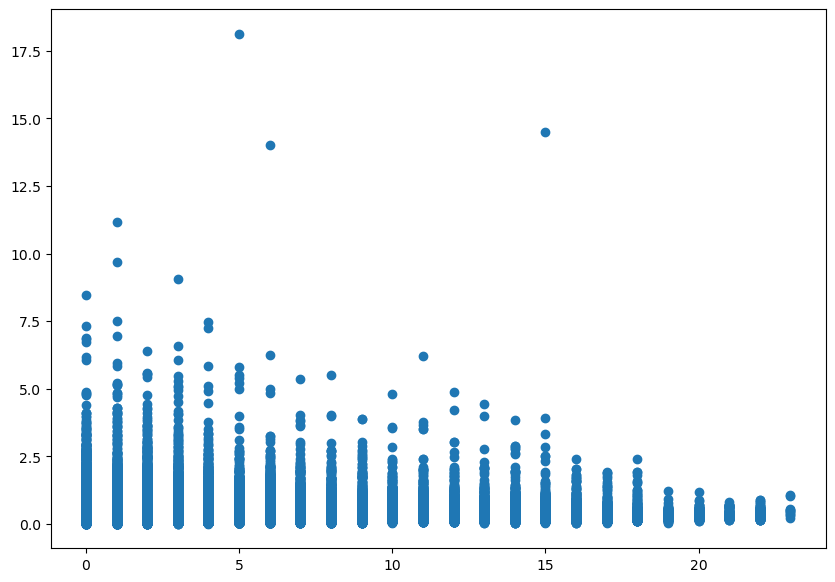

In [40]:
plt.scatter(get_real_cands(df_1)['max_num_consecutive_new'], get_real_cands(df_1)['snr_local_new'])

In [15]:
len(df_1)

564547

In [16]:
len(df_2)

128602

In [28]:
real = get_real_cands(df_2)
hmm = real[(real['sobel_norm_diffmax']<10) & (real['max_num_consecutive_new']>5)]

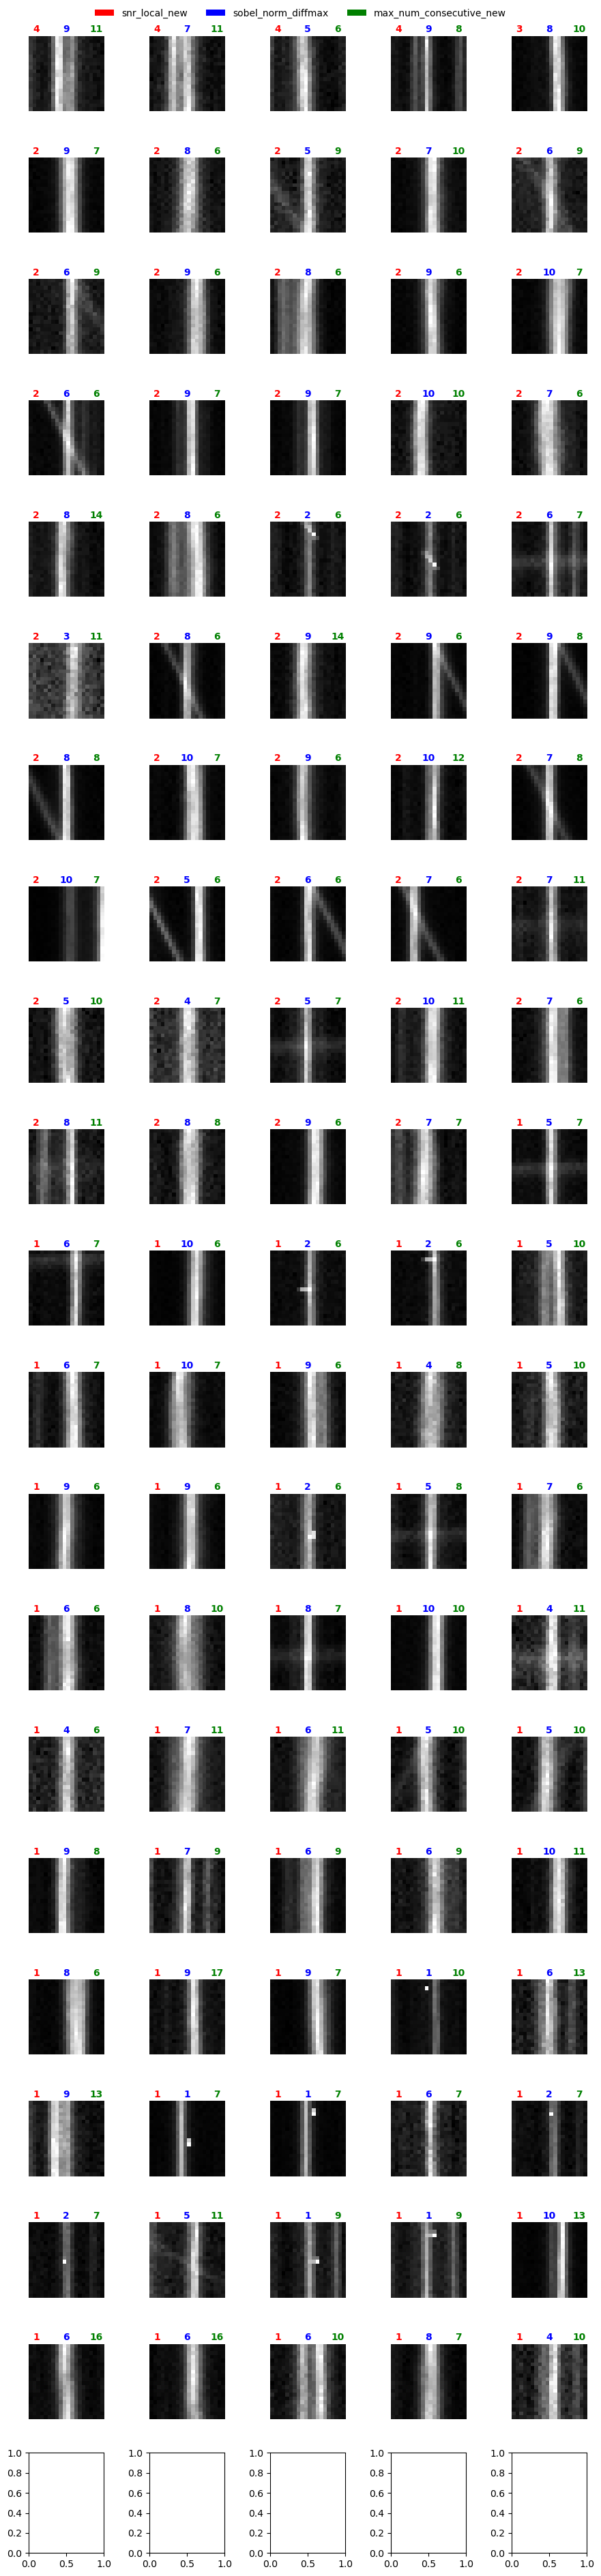

In [29]:
rff.inspect_df_w_stamp_color(hmm.sort_values('snr_local_new', ascending=False)[:100], titlecol=['snr_local_new', 'sobel_norm_diffmax','max_num_consecutive_new'])

In [31]:
df3 = rff.add_num_consecutive(df_2[df_2['snr_local_new']>1].sort_values('snr_local_new', ascending=False)[:1000], df_2[df_2['snr_local_new']>1])

In [39]:
len(df_2[df_2['snr_local_new']>5])

85

In [33]:
realish = get_real_cands(df3)

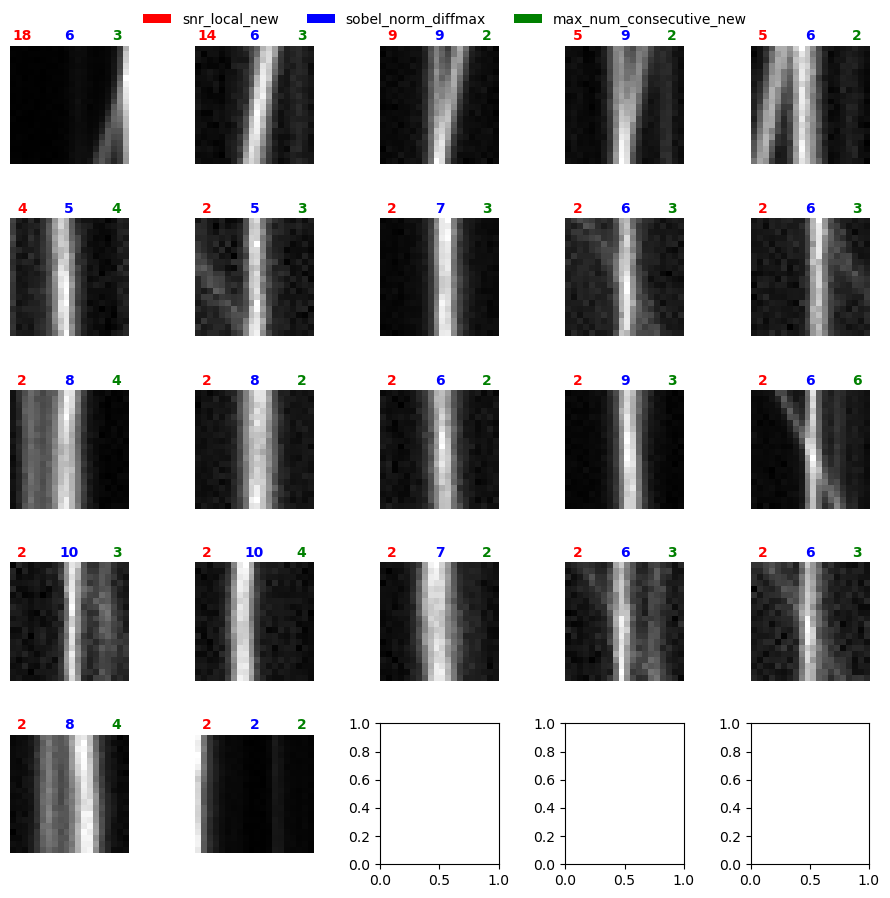

In [36]:
rff.inspect_df_w_stamp_color(realish[(realish['max_num_consecutive_new']>1) &(realish['sobel_norm_diffmax']<10)].sort_values('snr_local_new', ascending=False)[:100], titlecol=['snr_local_new', 'sobel_norm_diffmax','max_num_consecutive_new'])

In [42]:
df_new = get_real_cands(df_1, diff=10)

In [43]:
np.max(df_new['Diff'])

10.0

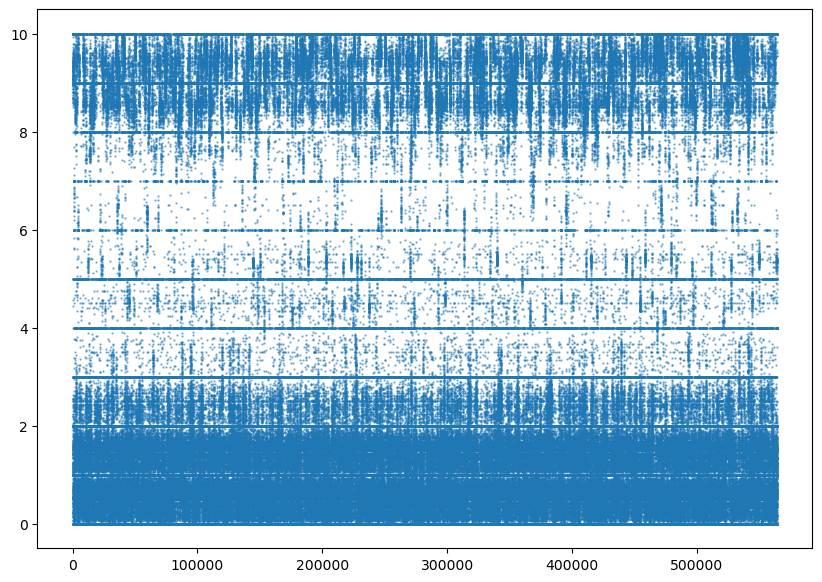

In [50]:
plt.scatter(df_new.index,df_new['Diff'], s=.5, alpha=.5)

In [56]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

In [59]:
#fraction of transients on the left vs right half of the streak, bin by diff, look at what that ratio is as 
#a function of diff. bins of 0.5
#see whether the star is on the left or right of the transient

0.0

Text(0.5, 0, 'Distance along postage stamp (0 at center)')

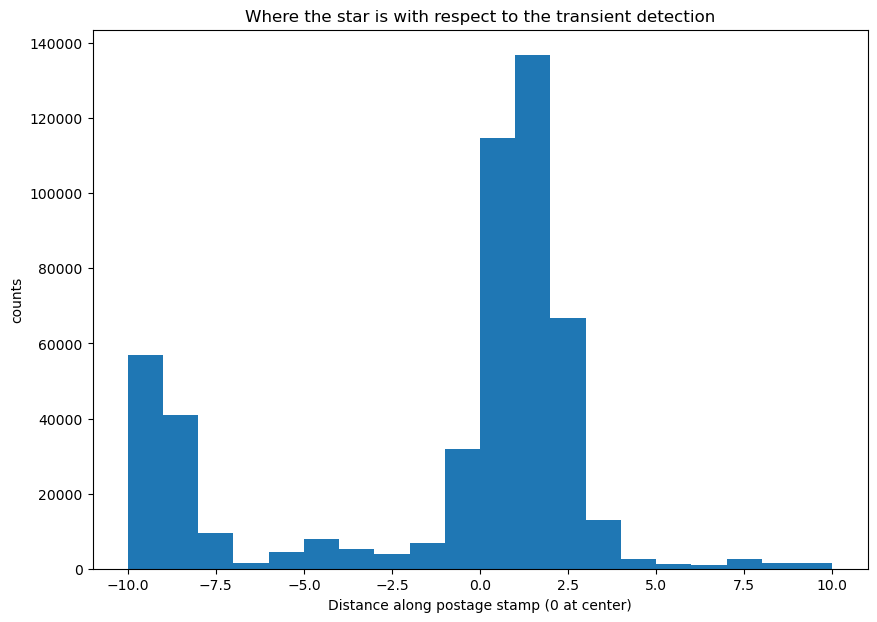

In [67]:
plt.hist(df_new['closest_x']-df_new['col_from_nn']-10, bins=20)
plt.title("Where the star is with respect to the transient detection")
plt.ylabel("counts")
plt.xlabel("Distance along postage stamp (0 at center)")

In [68]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

In [72]:
df_new.drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9",
                                                    "Unnamed: 0.10"
                                                    ]).loc[0]

filename                              ztf_20221020297847_000449_zr_c15_x_0006.
quad                                                                         4
type                                                                       pos
row_from_nn                                                               22.5
col_from_nn                                                             1273.0
detection_size                                                            14.0
closest_x                                                               1273.0
closest_y                                                               1665.0
Diff                                                                      10.0
snr_local                                                             0.114091
snr_global                                                            0.084354
noise_local                                                         127.918722
noise_global                                        

In [75]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

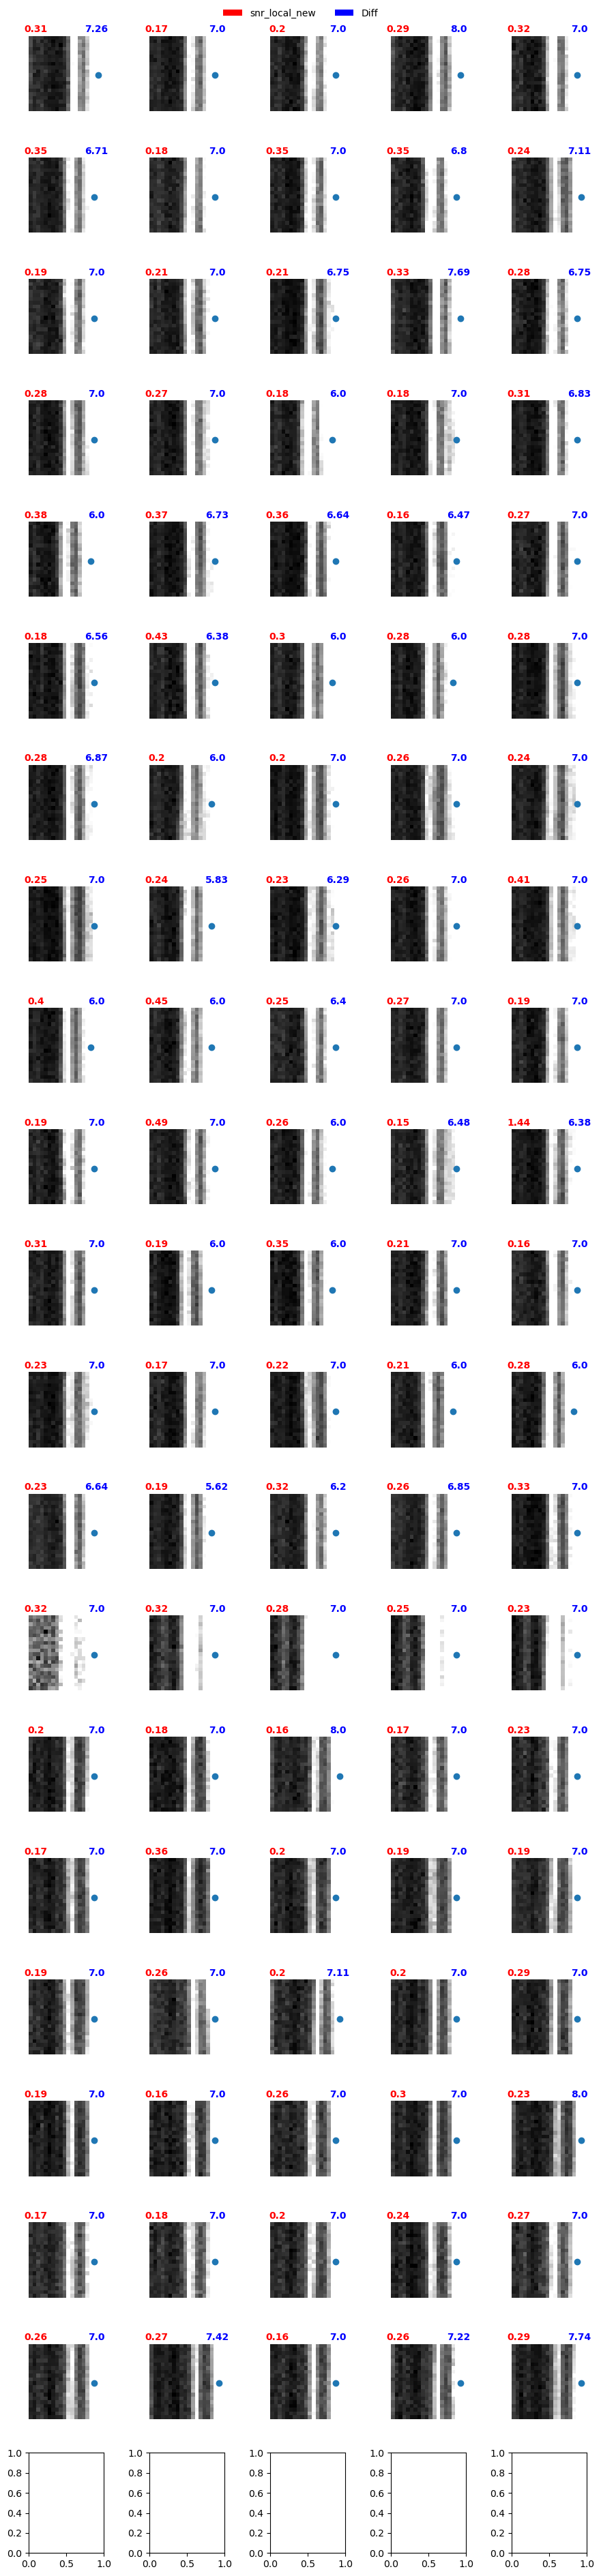

In [80]:
rff.inspect_df_w_stamp_color(df_new[(df_new['closest_x']-df_new['col_from_nn']-10)>5][:100], star=True,twodec=True,titlecol=['snr_local_new', 'Diff'], norm=True,clim=.08)

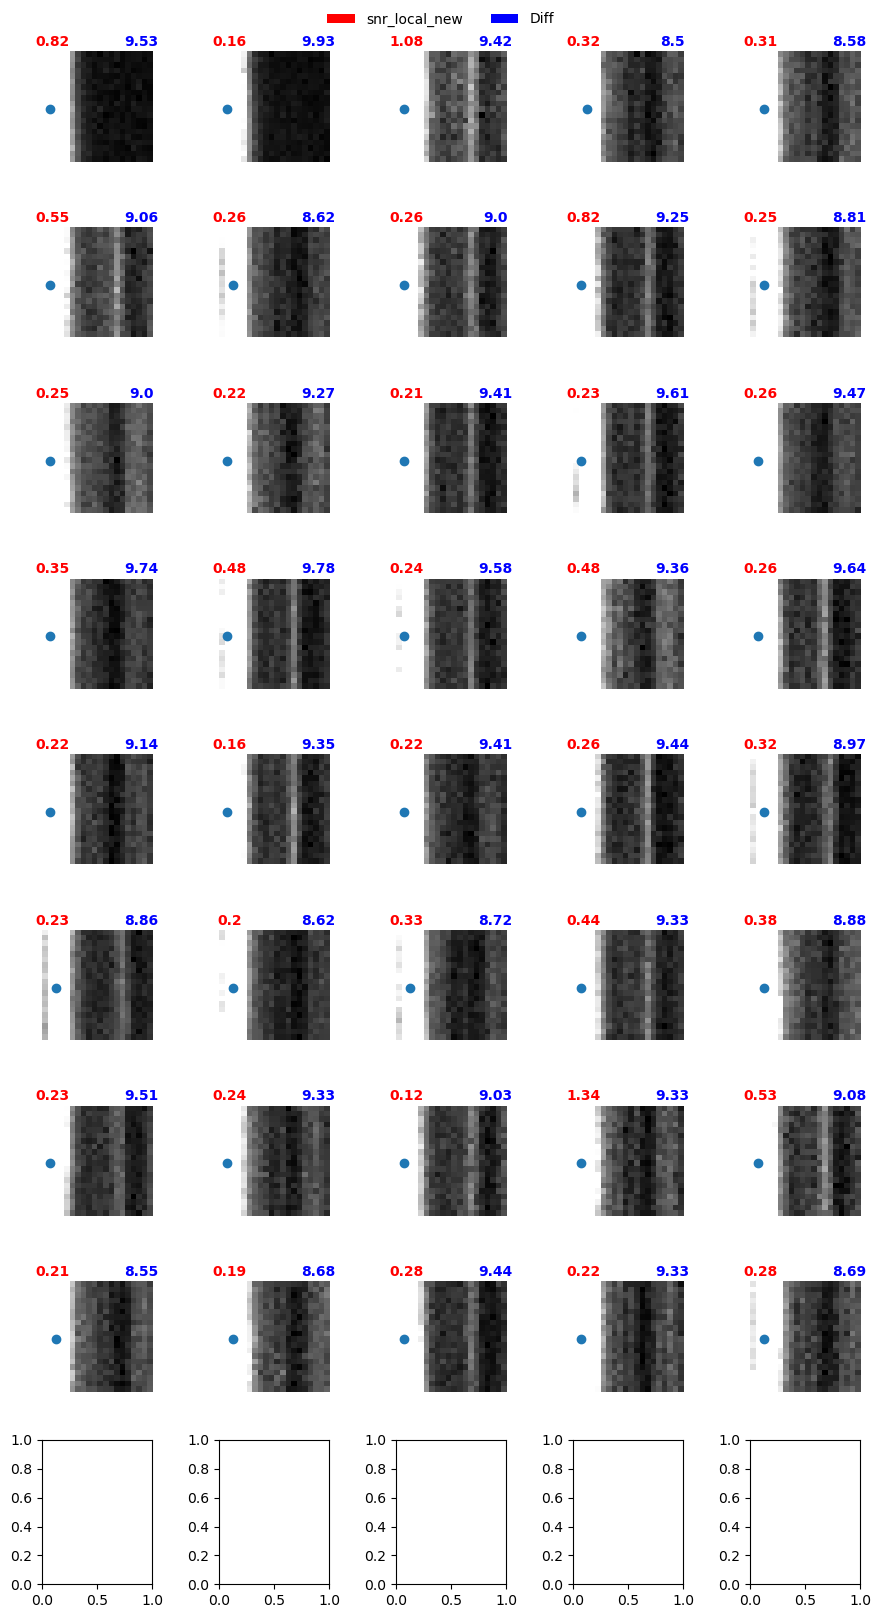

In [82]:
rff.inspect_df_w_stamp_color(df_new[(df_new['Diff']>8) & (df_new['Diff']<10)][:40], star=True,twodec=True,titlecol=['snr_local_new', 'Diff'], norm=True,clim=.08)

In [83]:
df_new[(df_new['Diff']>8) & (df_new['Diff']<10)][:40]

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,dup_indices,is_smaller_dup,num_in_file_new,num_consecutive_up_new,num_consecutive_down_new,possible_up_indices_new,possible_down_indices_new,max_num_consecutive_new,sat_flag,sat_neighbor
76,141,141,141,141,141,141,141,141,141,141,...,[138 142],0.0,233.0,0.0,0.0,[],[],0.0,0.0,0.0
109,205,205,205,205,205,205,205,205,205,205,...,[],0.0,233.0,0.0,0.0,[],[],0.0,0.0,0.0
358,742,742,742,742,742,742,742,742,742,742,...,[737 745],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
359,743,743,743,743,743,743,743,743,743,743,...,[741],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
361,746,746,746,746,746,746,746,746,746,746,...,[748],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
362,747,747,747,747,747,747,747,747,747,747,...,[],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
363,751,751,751,751,751,751,751,751,751,751,...,[750 753],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
364,752,752,752,752,752,752,752,752,752,752,...,[],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
365,754,754,754,754,754,754,754,754,754,754,...,[],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0
367,757,757,757,757,757,757,757,757,757,757,...,[],0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0


In [100]:
np.sum(df_new[(df_new['closest_x']-df_new['col_from_nn']-10)>5]['type']=='neg')/len(df_new[(df_new['closest_x']-df_new['col_from_nn']-10)>5])

0.7812872467222884

In [102]:
np.sum(df_new[(df_new['closest_x']-df_new['col_from_nn']-10)<(-5)]['type']=='pos')/len(df_new[(df_new['closest_x']-df_new['col_from_nn']-10)<(-5)])

0.9875559716322079

In [105]:
np.sum((df_new['closest_x']-df_new['col_from_nn']-10)<(-5))

113227

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020138241_000686_zi_c08_x_0004._extraction_predsarray_3_predsarray.npy


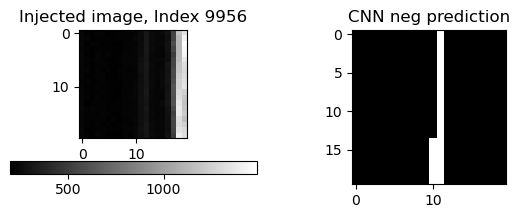

In [92]:
rff.inspect_stamp_and_map(df_new, 9956, eff=False, size=10)